In [1]:
# Cell 1: Data loading & structural inspection
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import warnings
warnings.filterwarnings("ignore")

from scipy import stats
from scipy.stats import pearsonr, spearmanr, linregress
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(repr(obj))

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RANDOM_STATE   = 42
MISS_THRESHOLD = 10
FILE_PATH      = r"D:\miniproject\data\bronze\delhi_air_weather.csv"

df = pd.read_csv(FILE_PATH, parse_dates=["timestamp"])
print("Shape:", df.shape)
df.info()

print("\nTimestamp range:", df["timestamp"].min(), "->", df["timestamp"].max())
print("Stations:", df["station_name"].nunique())

dup_per_station = (
    df.groupby("station_name")["timestamp"]
      .apply(lambda s: s.duplicated().sum())
      .sort_values(ascending=False)
)
print("\nDuplicate timestamps per station:\n", dup_per_station)
print("\nTotal duplicated (station, timestamp) rows:",
      int(df.duplicated(subset=["station_name", "timestamp"]).sum()))

coverage = (
    df.groupby("station_name")
      .agg(n=("PM2.5 (µg/m³)", "count"),
           first=("timestamp", "min"),
           last=("timestamp", "max"))
      .sort_values("n", ascending=False)
)
print("\nStation coverage:\n", coverage)

coord_cols  = ["latitude_x", "latitude_y", "longitude_x", "longitude_y"]
coord_dupes = df[[c for c in coord_cols if c in df.columns]].drop_duplicates()
print("\nUnique coordinate rows:", len(coord_dupes))
print(coord_dupes.head())

Shape: (131400, 40)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131400 entries, 0 to 131399
Data columns (total 40 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   timestamp              131400 non-null  datetime64[ns]
 1   PM2.5 (µg/m³)          124519 non-null  float64       
 2   PM10 (µg/m³)           124022 non-null  float64       
 3   NO (µg/m³)             126451 non-null  float64       
 4   NO2 (µg/m³)            125684 non-null  float64       
 5   NOx (ppb)              126898 non-null  float64       
 6   NH3 (µg/m³)            119092 non-null  float64       
 7   SO2 (µg/m³)            117398 non-null  float64       
 8   CO (mg/m³)             126278 non-null  float64       
 9   Ozone (µg/m³)          125759 non-null  float64       
 10  Benzene (µg/m³)        112370 non-null  float64       
 11  Toluene (µg/m³)        95900 non-null   float64       
 12  Xylene (µg/m³)         2

In [2]:
# Cell 2: Missing-value analysis & cleaning
miss = (df.isnull().mean() * 100).round(2).sort_values(ascending=False)
print("Missing % per column:\n", miss)

cols_over_10 = miss[miss > MISS_THRESHOLD].index.tolist()
print(f"\nDropping {len(cols_over_10)} columns (> {MISS_THRESHOLD}% missing):")
print(cols_over_10)

df1 = df.drop(columns=cols_over_10).copy()
df1.drop(columns=["NOx (ppb)", "precipitation"], inplace=True, errors="ignore")
print(f"\nFinal shape: {df1.shape}")
df1.info()

POLLUTANTS = ["PM2.5 (µg/m³)", "PM10 (µg/m³)", "NO (µg/m³)", "NO2 (µg/m³)",
              "NH3 (µg/m³)", "CO (mg/m³)", "Ozone (µg/m³)"]
METEO = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m",
         "wind_direction_10m", "rain", "surface_pressure",
         "boundary_layer_height", "wind_u", "wind_v"]
POLLUTANTS = [c for c in POLLUTANTS if c in df1.columns]
METEO      = [c for c in METEO      if c in df1.columns]
print("\nKept pollutants:", POLLUTANTS)
print("Kept meteo:     ", METEO)

Missing % per column:
 O Xylene (µg/m³)         100.00
Xylene (µg/m³)            98.36
MP-Xylene (µg/m³)         85.05
Eth-Benzene (µg/m³)       84.44
VWS (m/s)                 80.48
RF (mm)                   40.91
BP (mmHg)                 35.08
AT (°C)                   28.15
Toluene (µg/m³)           27.02
WS (m/s)                  24.38
SR (W/mt2)                18.41
WD (deg)                  15.68
RH (%)                    15.65
Benzene (µg/m³)           14.48
TOT-RF (mm)               13.33
SO2 (µg/m³)               10.66
NH3 (µg/m³)                9.37
PM10 (µg/m³)               5.61
PM2.5 (µg/m³)              5.24
NO2 (µg/m³)                4.35
Ozone (µg/m³)              4.29
CO (mg/m³)                 3.90
NO (µg/m³)                 3.77
NOx (ppb)                  3.43
timestamp                  0.00
station_name               0.00
latitude_x                 0.00
longitude_x                0.00
temperature_2m             0.00
relative_humidity_2m       0.00
wind_speed_10m   

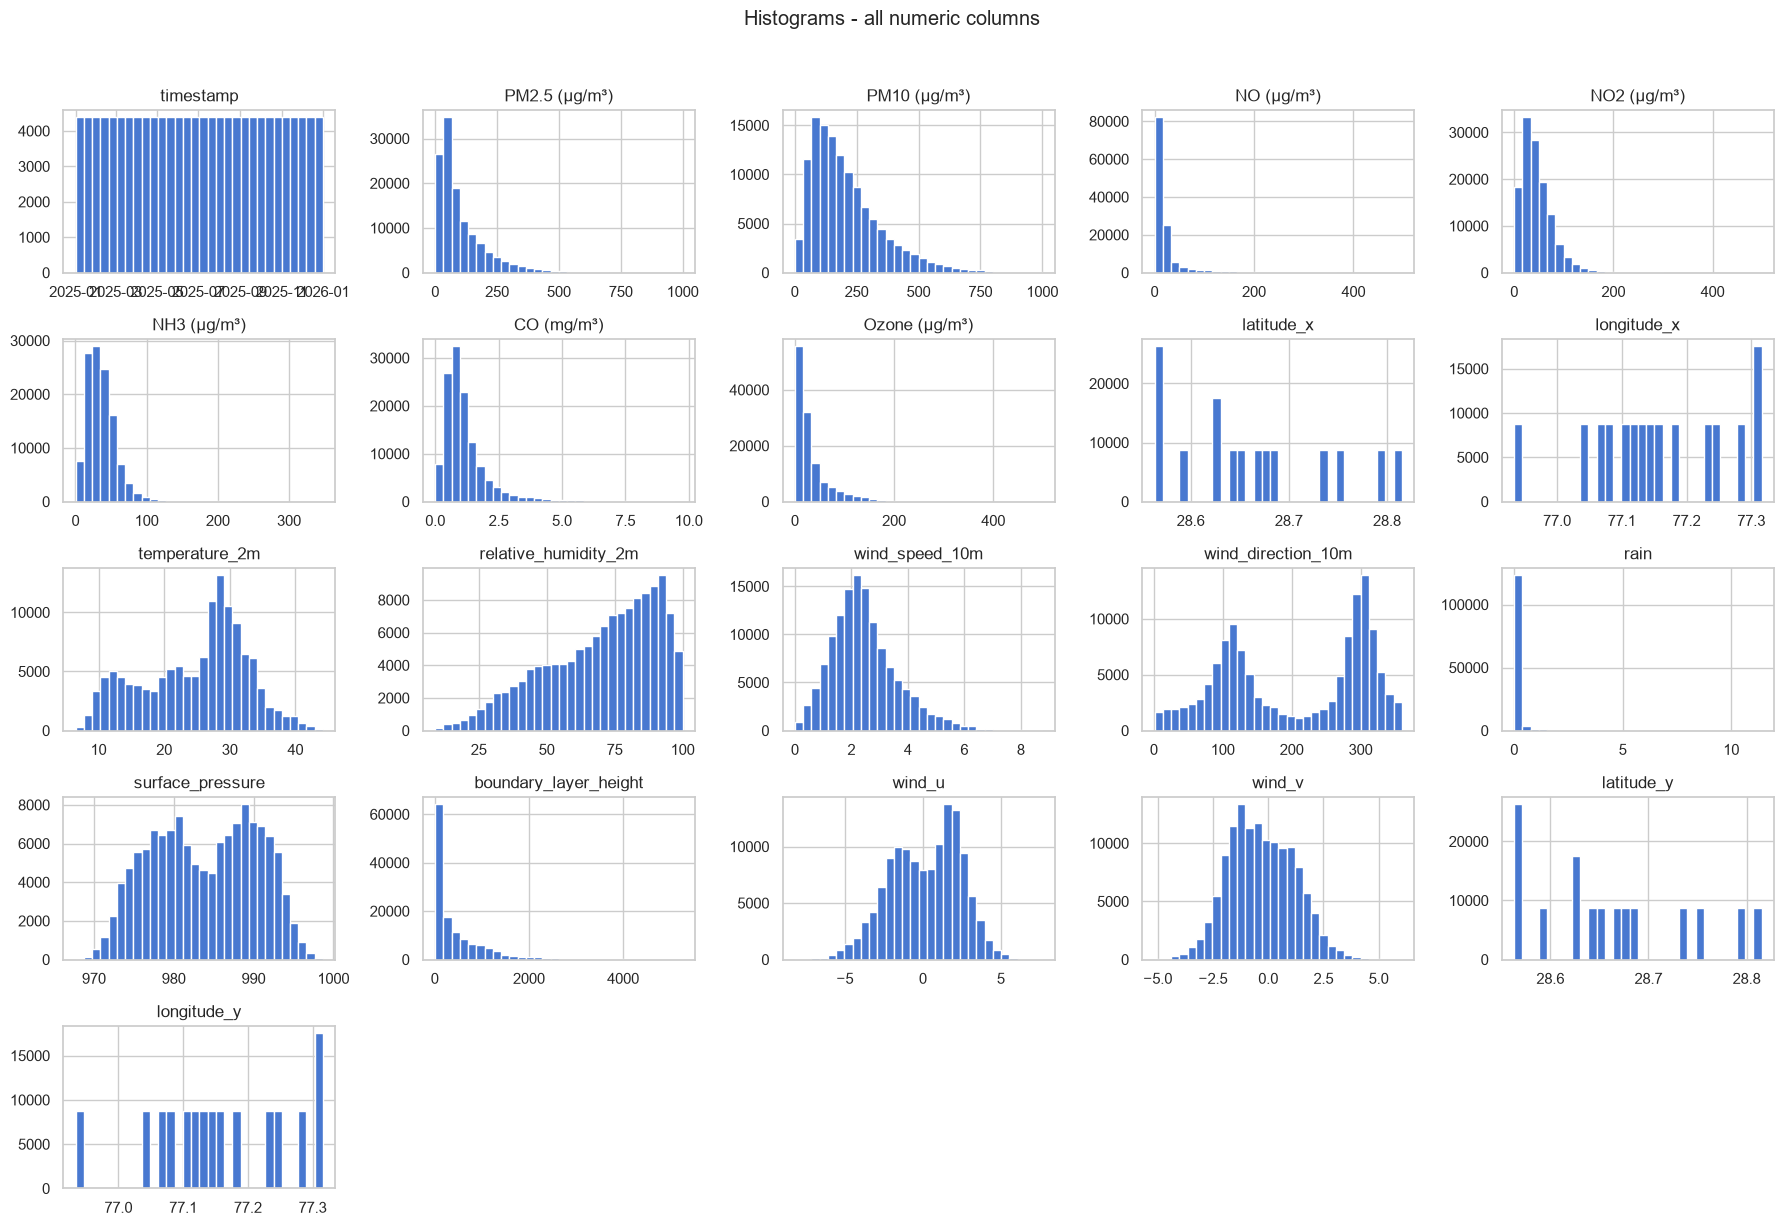

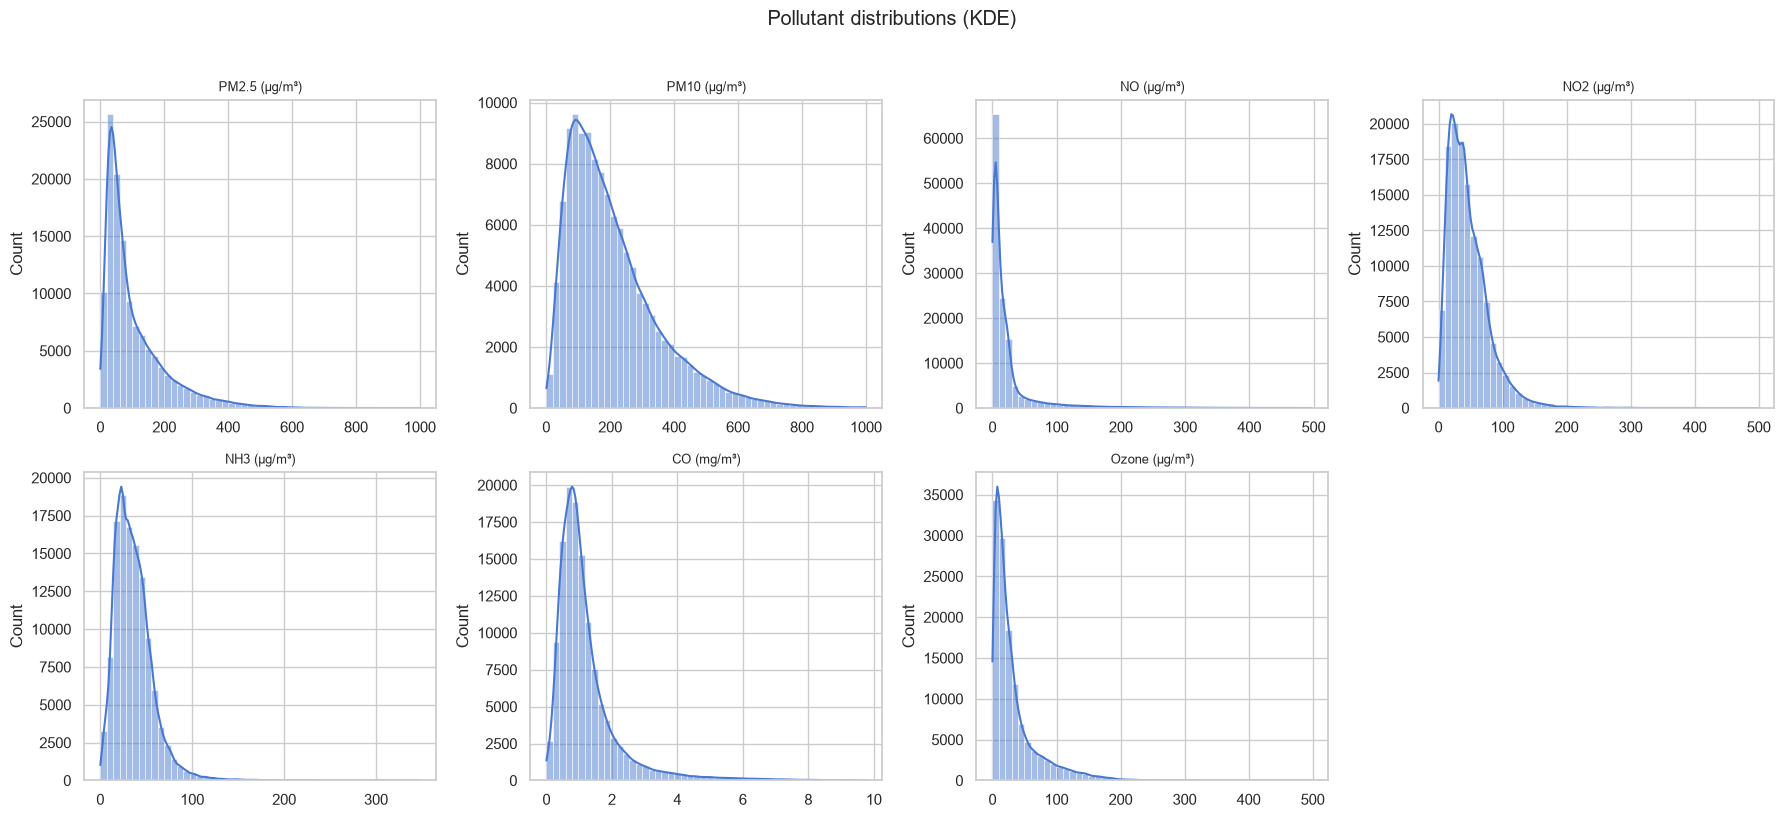

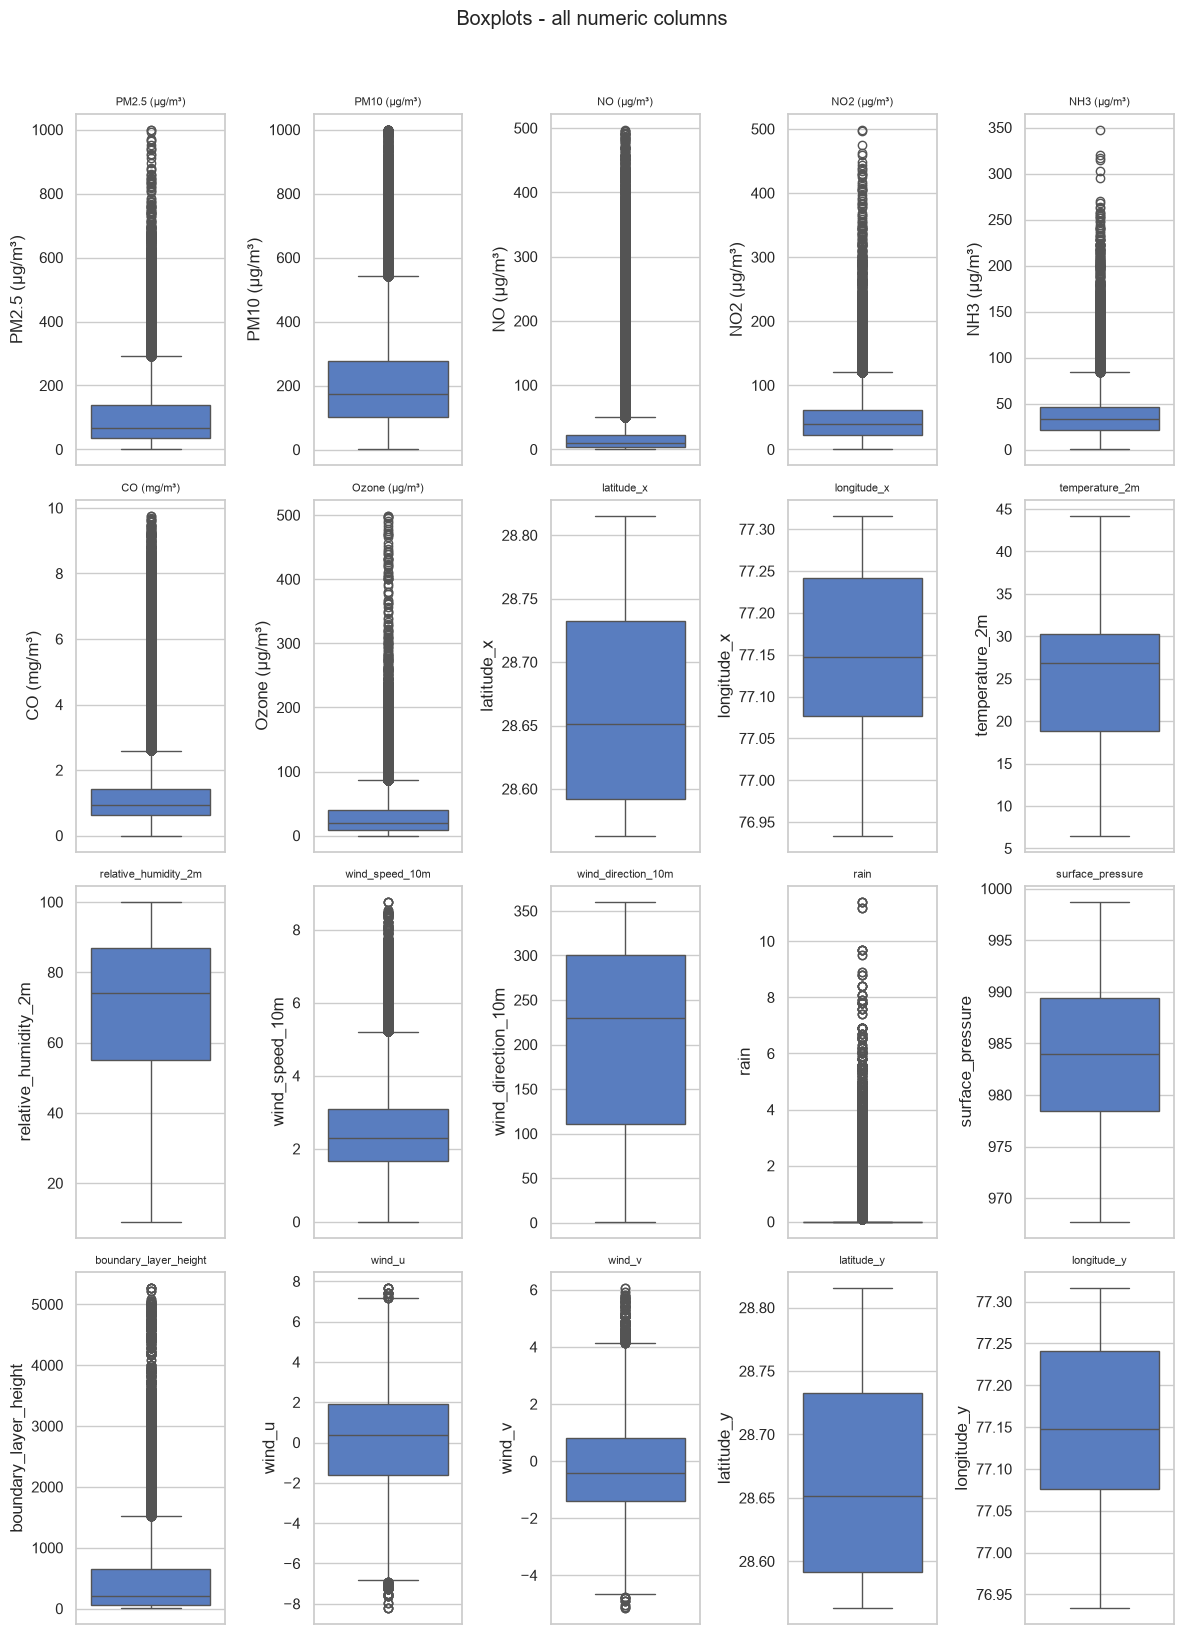

In [3]:
# Cell 3: Univariate analysis
df1.hist(bins=30, figsize=(18, 12))
plt.suptitle("Histograms - all numeric columns", y=1.02)
plt.tight_layout(); plt.show()

if POLLUTANTS:
    n = len(POLLUTANTS); ncols = 4; nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
    axes = axes.flatten()
    for ax, col in zip(axes, POLLUTANTS):
        sns.histplot(df1[col].dropna(), kde=True, bins=50, ax=ax)
        ax.set_title(col, fontsize=9); ax.set_xlabel("")
    for ax in axes[n:]:
        ax.set_visible(False)
    plt.suptitle("Pollutant distributions (KDE)", y=1.02)
    plt.tight_layout(); plt.show()

numeric_cols = df1.select_dtypes(include="number").columns.tolist()
n_rows = 4; n_cols = math.ceil(len(numeric_cols) / n_rows)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows), squeeze=False)
axes = axes.ravel()
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df1[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
for i in range(len(numeric_cols), len(axes)):
    axes[i].set_visible(False)
plt.suptitle("Boxplots - all numeric columns", y=1.02)
plt.tight_layout(); plt.show()

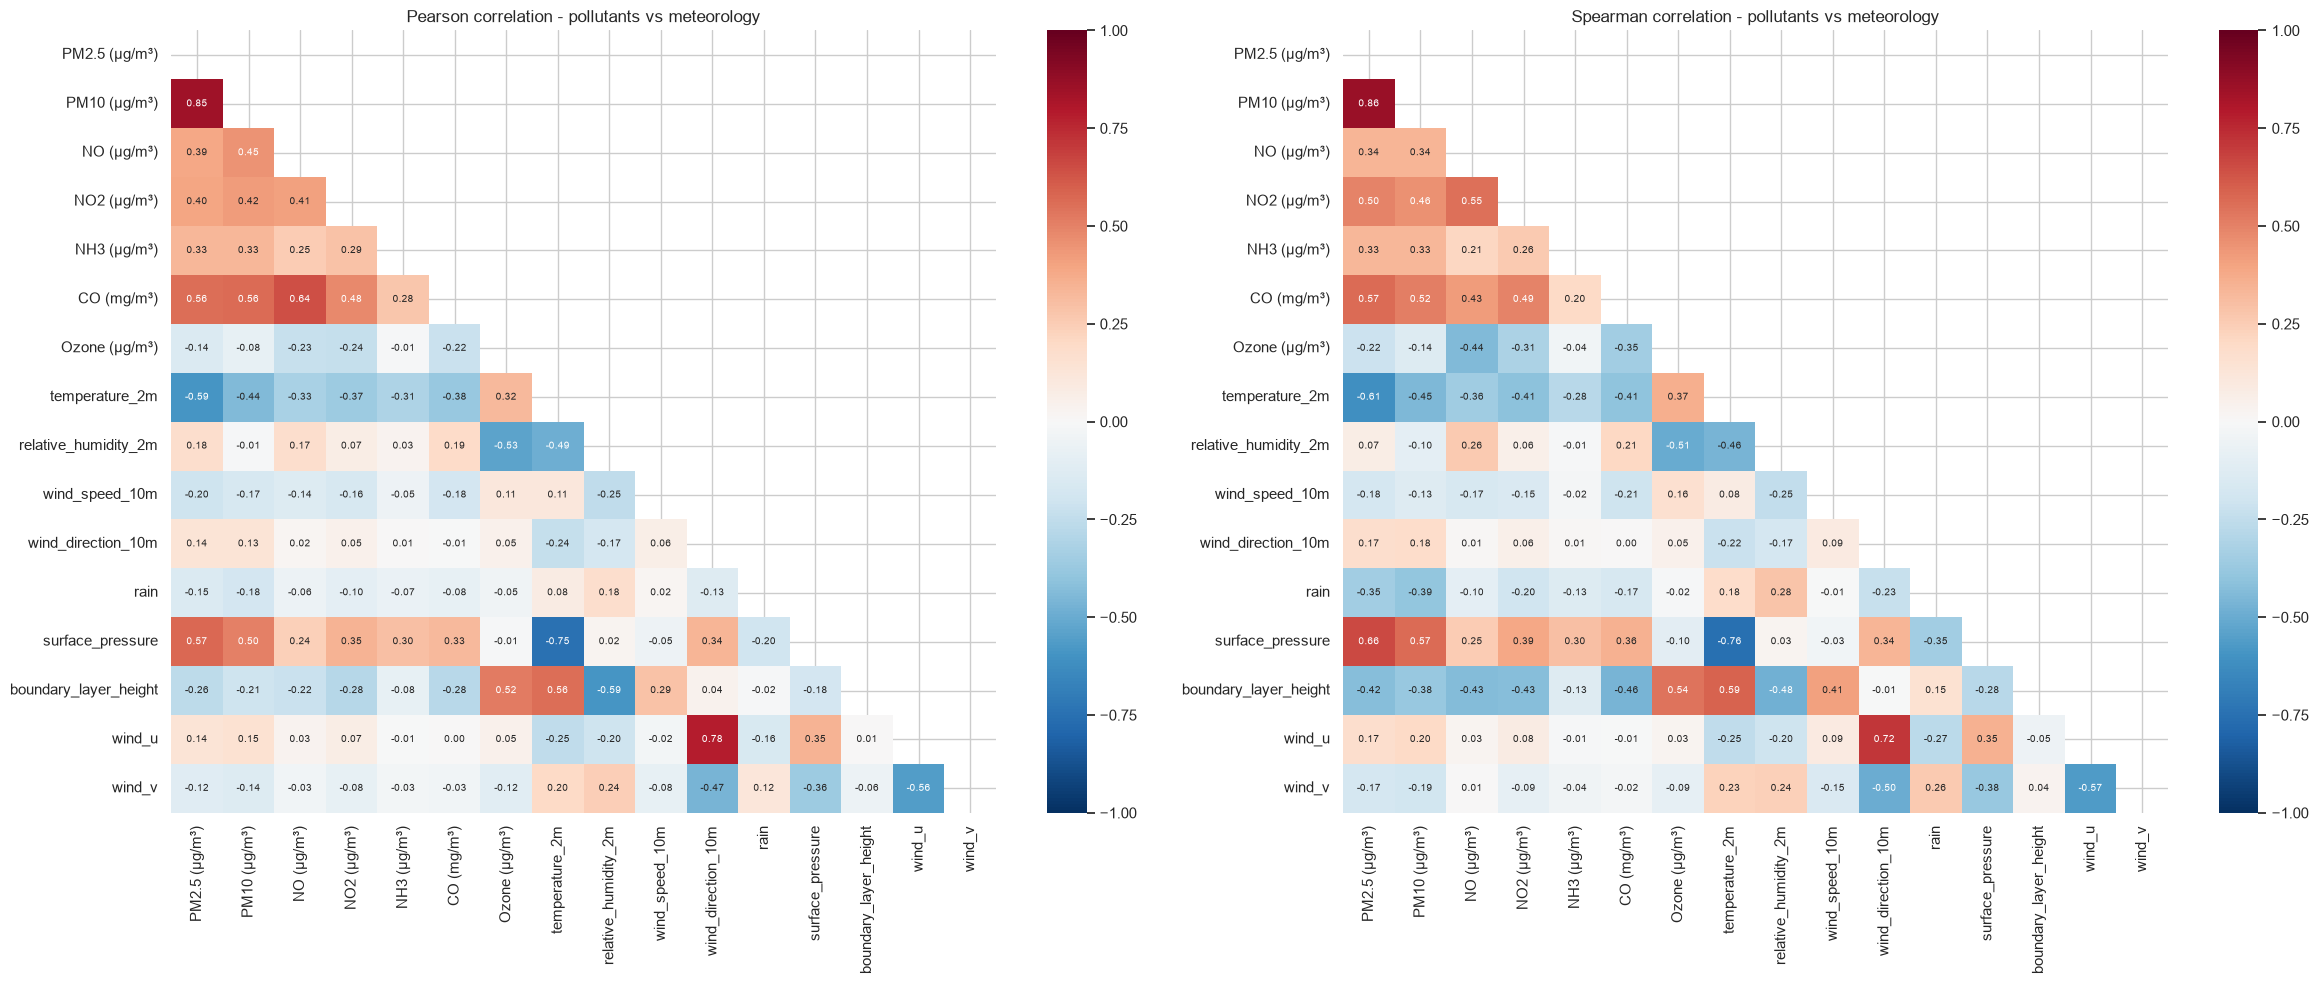

Pearson correlation with PM2.5 (abs-sorted):
 PM10 (µg/m³)             0.848
temperature_2m          -0.592
surface_pressure         0.572
CO (mg/m³)               0.556
NO2 (µg/m³)              0.398
NO (µg/m³)               0.390
NH3 (µg/m³)              0.331
boundary_layer_height   -0.262
wind_speed_10m          -0.204
relative_humidity_2m     0.177
rain                    -0.145
Ozone (µg/m³)           -0.142
wind_direction_10m       0.137
wind_u                   0.136
wind_v                  -0.125
Name: PM2.5 (µg/m³), dtype: float64

Spatial PM2.5 vs NO2 across stations: r=-0.159, p=0.572


In [4]:
# Cell 4: Correlation analysis
num_cols = [c for c in (POLLUTANTS + METEO) if c in df1.columns]
corr_p = df1[num_cols].corr(method="pearson")
corr_s = df1[num_cols].corr(method="spearman")
mask   = np.triu(np.ones_like(corr_p, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(24, 10))
for ax, C, name in [(axes[0], corr_p, "Pearson"), (axes[1], corr_s, "Spearman")]:
    sns.heatmap(C, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
                vmin=-1, vmax=1, center=0, ax=ax, annot_kws={"size": 7})
    ax.set_title(f"{name} correlation - pollutants vs meteorology")
plt.tight_layout(); plt.show()

pm25_col = "PM2.5 (µg/m³)"
if pm25_col in corr_p.columns:
    pm25_rank = (corr_p[pm25_col].drop(pm25_col)
                 .sort_values(key=np.abs, ascending=False))
    print("Pearson correlation with PM2.5 (abs-sorted):\n", pm25_rank.round(3))

if "NO2 (µg/m³)" in df1.columns:
    st_means = df1.groupby("station_name")[[pm25_col, "NO2 (µg/m³)"]].mean().dropna()
    if len(st_means) > 2:
        r_sp, p_sp = pearsonr(st_means[pm25_col], st_means["NO2 (µg/m³)"])
        print(f"\nSpatial PM2.5 vs NO2 across stations: r={r_sp:.3f}, p={p_sp:.3f}")

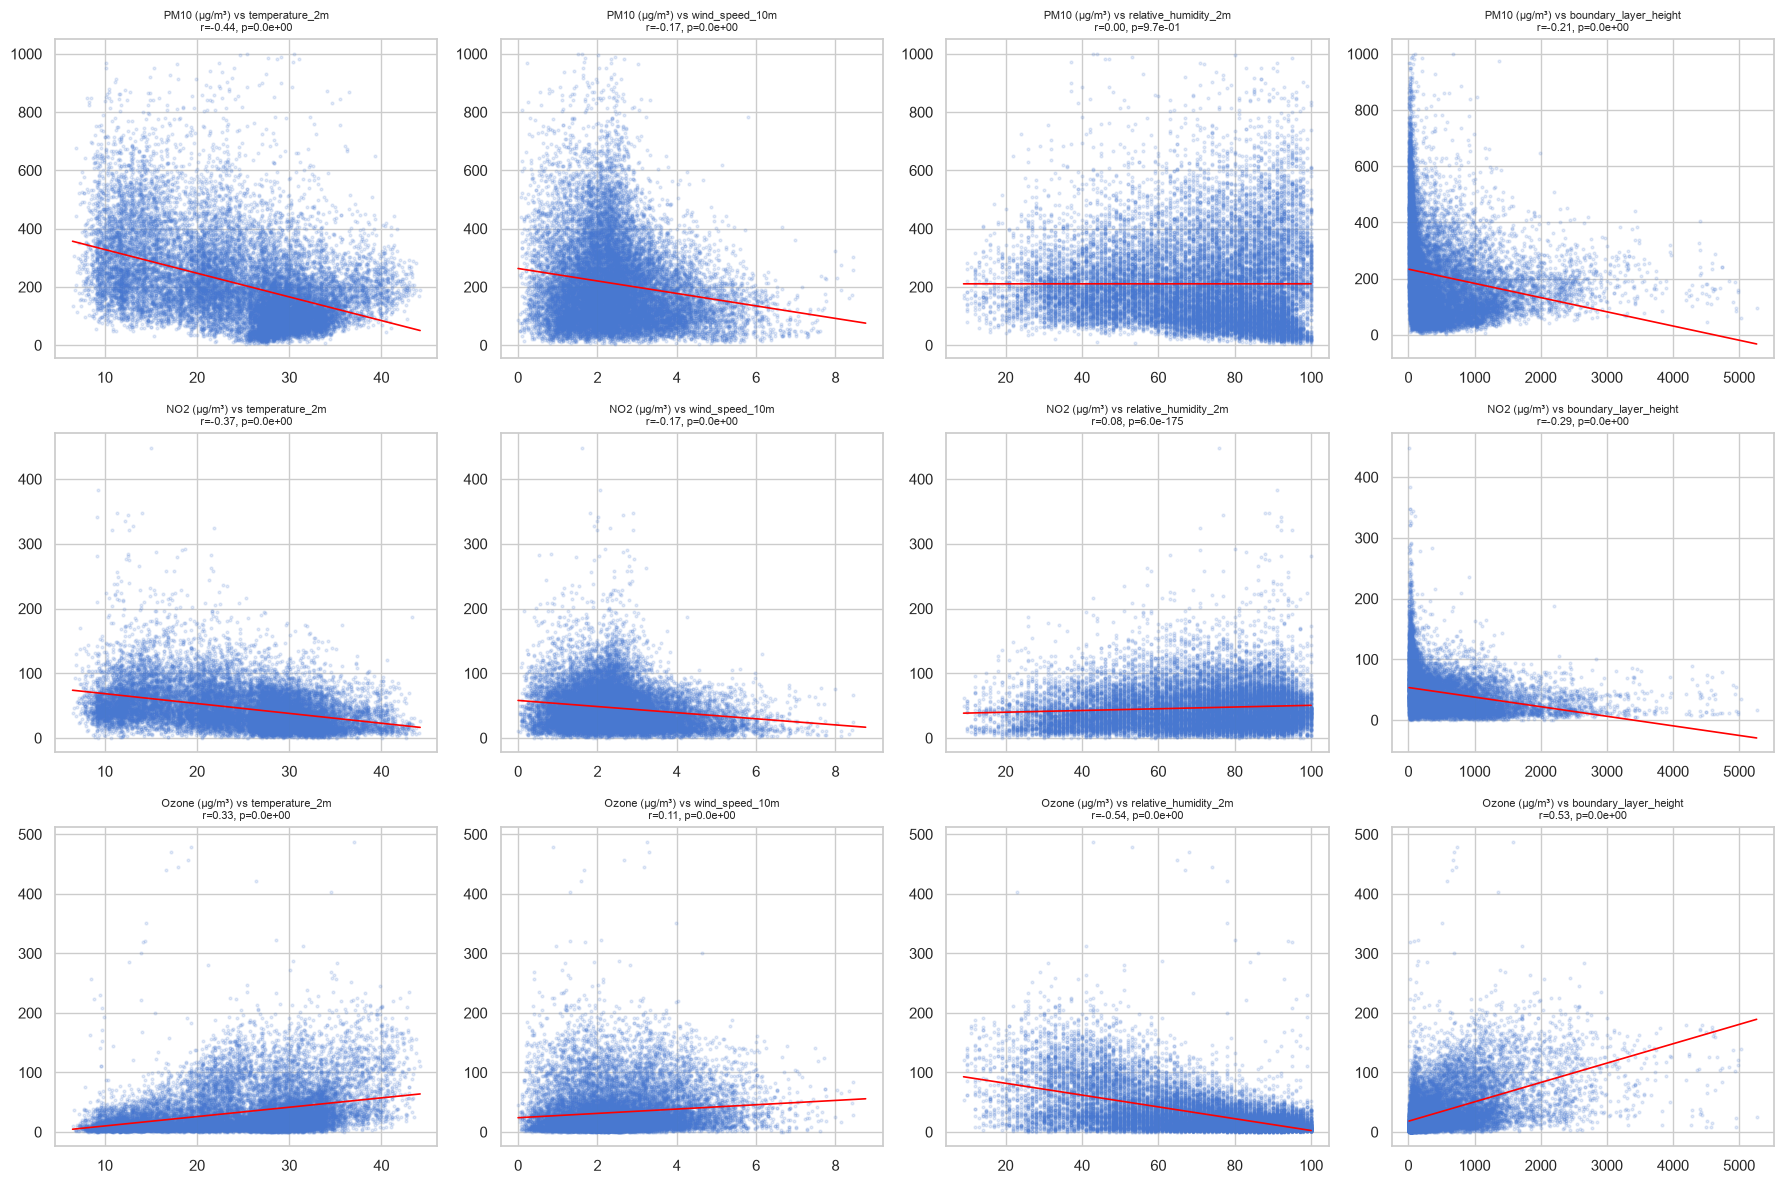

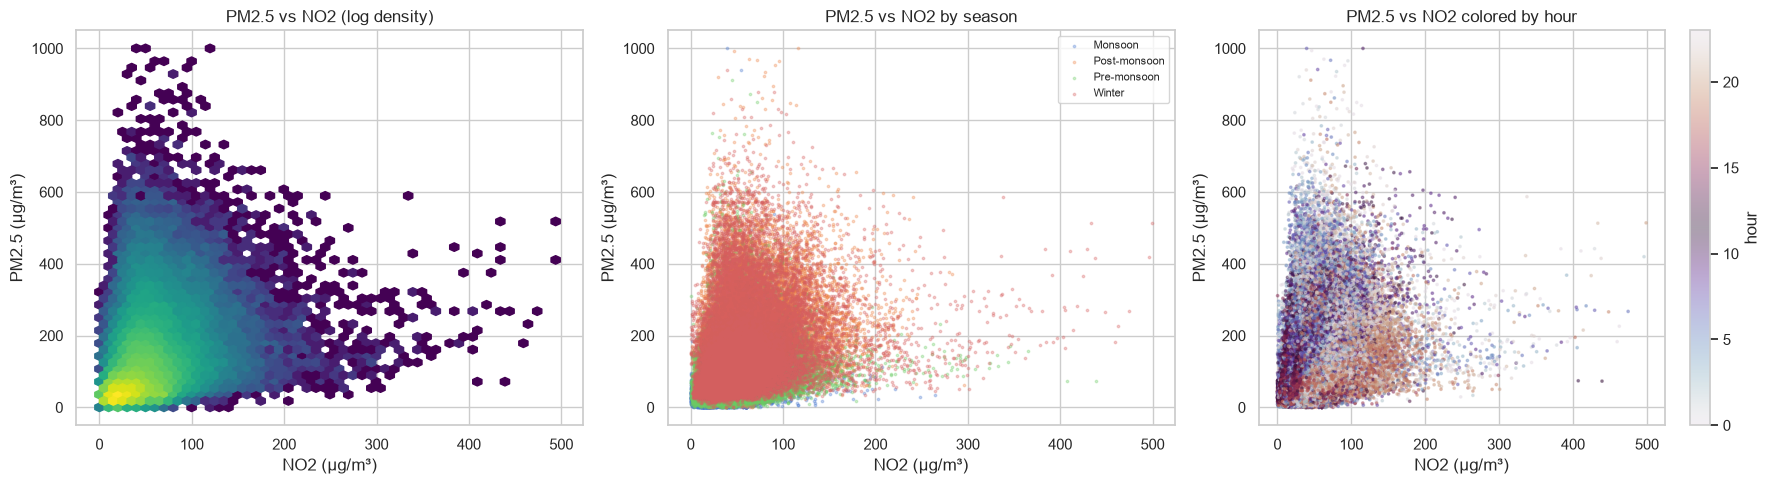

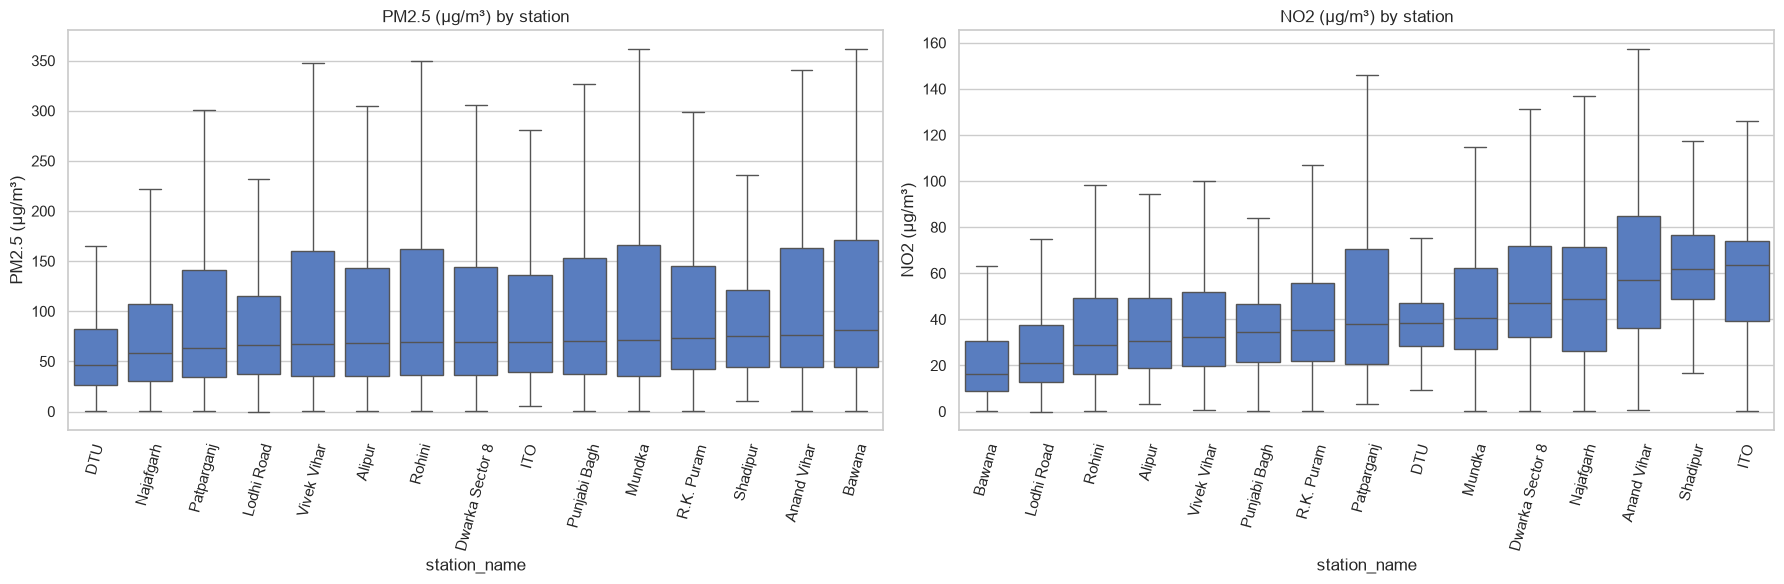

Station-level PM2.5 summary:
                    mean  median  observations
station_name                                 
Bawana           123.44   81.00          8560
Anand Vihar      121.88   76.00          8144
Rohini           115.93   69.00          8636
Mundka           115.49   71.00          8502
Vivek Vihar      114.71   67.00          8472
R.K. Puram       110.34   73.00          8358
Punjabi Bagh     109.94   70.00          8100
ITO              102.76   69.25          8272
Patparganj       102.03   63.00          8585
Dwarka Sector 8  101.92   69.00          8602
Alipur           100.64   68.00          8499
Shadipur          91.84   75.70          8047
Lodhi Road        86.34   66.68          7118
Najafgarh         79.28   58.00          8276
DTU               76.96   46.06          8348


In [5]:
# Cell 5: Bivariate analysis
pm25_col = "PM2.5 (µg/m³)"
KEY_METEO = [c for c in ["temperature_2m", "wind_speed_10m",
                         "relative_humidity_2m", "boundary_layer_height"]
             if c in df1.columns]
KEY_POLL  = [c for c in ["PM10 (µg/m³)", "NO2 (µg/m³)", "Ozone (µg/m³)"]
             if c in df1.columns]

# 5a. Scatter + linregress grid
if KEY_METEO and KEY_POLL:
    sub = df1[KEY_METEO + KEY_POLL + [pm25_col]].dropna()
    MAX_PTS = 20_000
    plot_df = sub.sample(MAX_PTS, random_state=0) if len(sub) > MAX_PTS else sub
    fig, axes = plt.subplots(len(KEY_POLL), len(KEY_METEO),
                             figsize=(18, 4 * len(KEY_POLL)),
                             sharex=False, squeeze=False)
    for i, pol in enumerate(KEY_POLL):
        for j, met in enumerate(KEY_METEO):
            ax = axes[i, j]
            x_full = sub[met].to_numpy(); y_full = sub[pol].to_numpy()
            lr = linregress(x_full, y_full)
            ax.scatter(plot_df[met], plot_df[pol], s=4, alpha=0.15, rasterized=True)
            xr = np.array([x_full.min(), x_full.max()])
            ax.plot(xr, lr.intercept + lr.slope * xr, color="red", lw=1.2)
            ax.set_title(f"{pol} vs {met}\nr={lr.rvalue:.2f}, p={lr.pvalue:.1e}",
                         fontsize=8)
            ax.set_xlabel(""); ax.set_ylabel("")
    plt.tight_layout(); plt.show()

# 5b. Hexbin + seasonal overlay + hour color
if "NO2 (µg/m³)" in df1.columns:
    season_bi = np.select(
        [df1["timestamp"].dt.month.isin([12, 1, 2]),
         df1["timestamp"].dt.month.isin([3, 4, 5]),
         df1["timestamp"].dt.month.isin([6, 7, 8, 9]),
         df1["timestamp"].dt.month.isin([10, 11])],
        ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"],
        default="Other")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].hexbin(df1["NO2 (µg/m³)"], df1[pm25_col],
                   gridsize=50, cmap="viridis", bins="log")
    axes[0].set_title("PM2.5 vs NO2 (log density)")
    for s, sub_s in df1.groupby(season_bi):
        axes[1].scatter(sub_s["NO2 (µg/m³)"], sub_s[pm25_col],
                        s=3, alpha=0.3, label=s)
    axes[1].set_title("PM2.5 vs NO2 by season"); axes[1].legend(fontsize=8)
    sc = axes[2].scatter(df1["NO2 (µg/m³)"], df1[pm25_col],
                         c=df1["timestamp"].dt.hour,
                         cmap="twilight", s=3, alpha=0.4)
    plt.colorbar(sc, ax=axes[2], label="hour")
    axes[2].set_title("PM2.5 vs NO2 colored by hour")
    for ax in axes:
        ax.set_xlabel("NO2 (µg/m³)"); ax.set_ylabel("PM2.5 (µg/m³)")
    plt.tight_layout(); plt.show()

# 5c. Station-wise boxplots + summary
station_pols = [c for c in [pm25_col, "NO2 (µg/m³)"] if c in df1.columns]
if station_pols:
    fig, axes = plt.subplots(1, len(station_pols),
                             figsize=(9 * len(station_pols), 6), squeeze=False)
    for ax, pol in zip(axes.flatten(), station_pols):
        order = df1.groupby("station_name")[pol].median().sort_values().index
        sns.boxplot(data=df1, x="station_name", y=pol, order=order,
                    ax=ax, showfliers=False)
        ax.set_title(f"{pol} by station"); ax.tick_params(axis="x", rotation=75)
    plt.tight_layout(); plt.show()

    print("Station-level PM2.5 summary:\n",
          df1.groupby("station_name")[pm25_col]
             .agg(mean="mean", median="median", observations="count")
             .sort_values("mean", ascending=False).round(2))

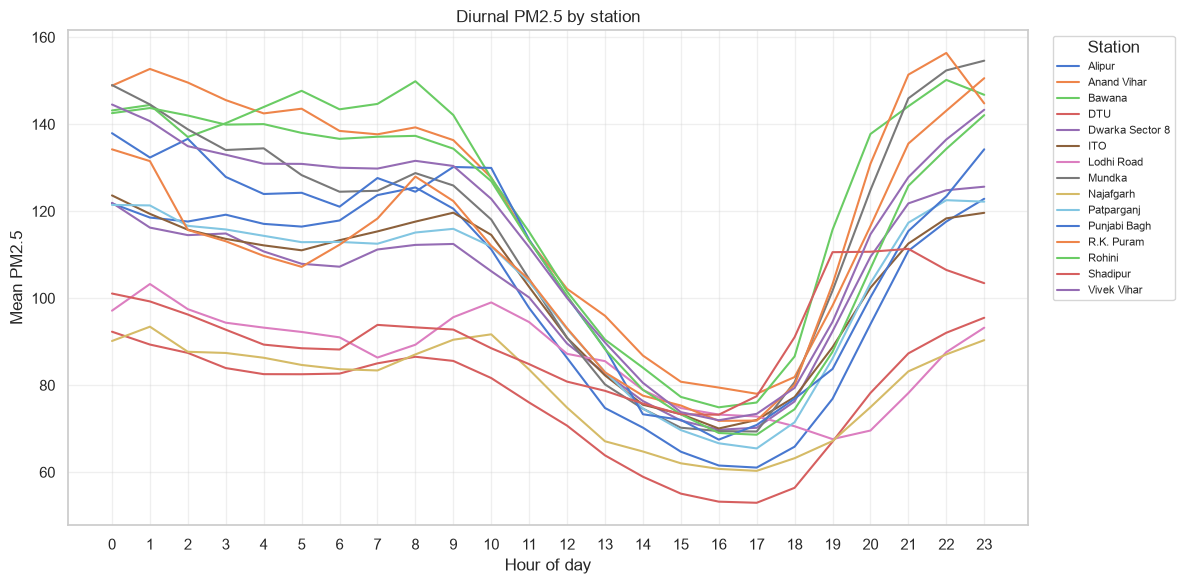

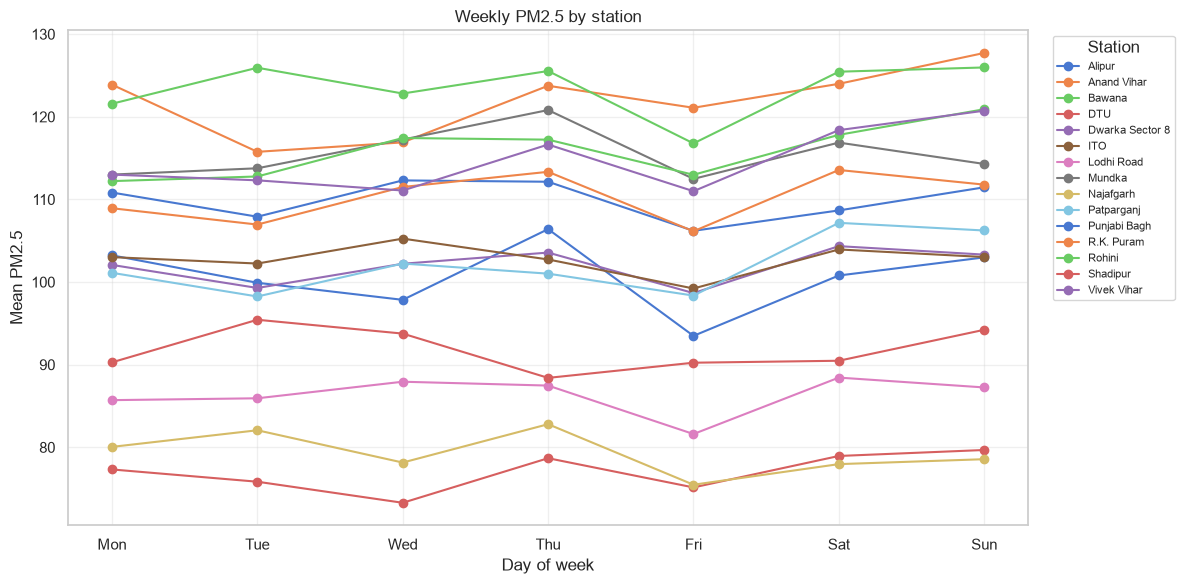

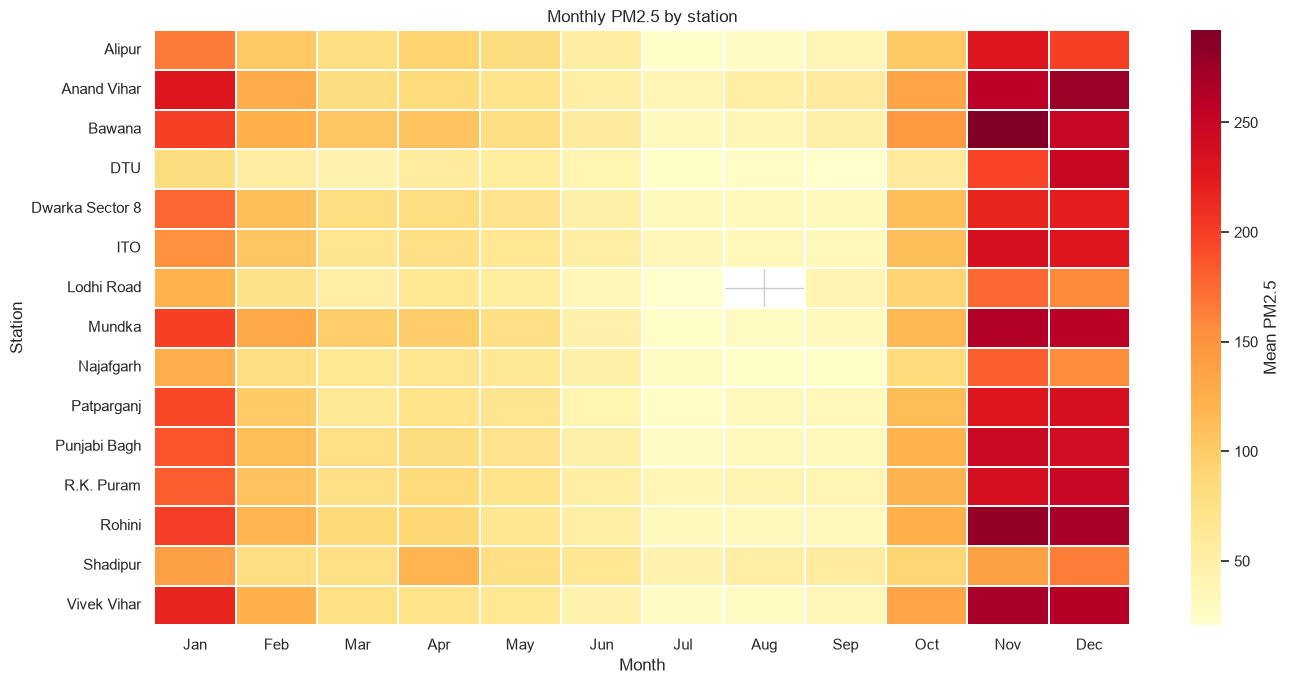

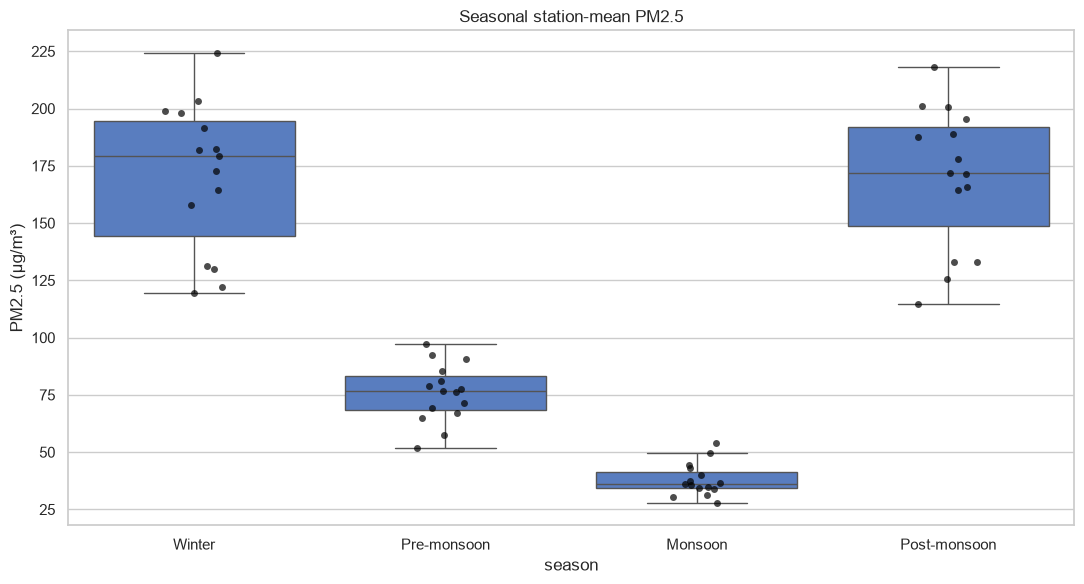

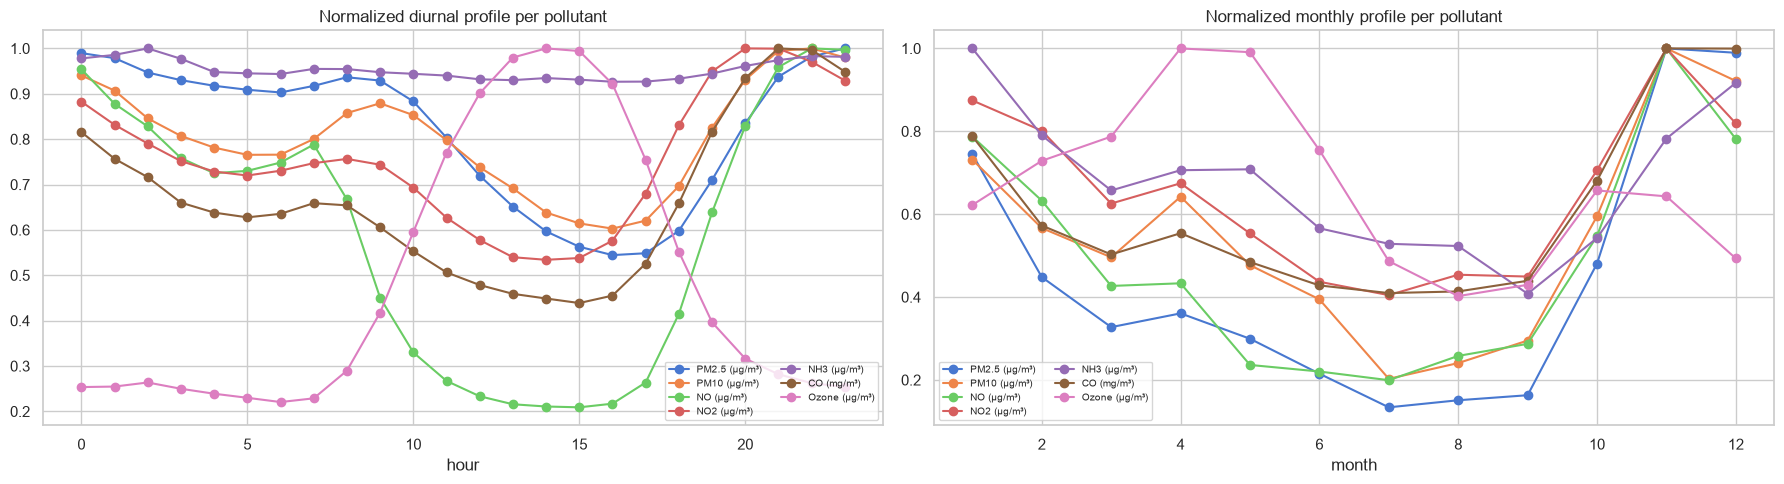

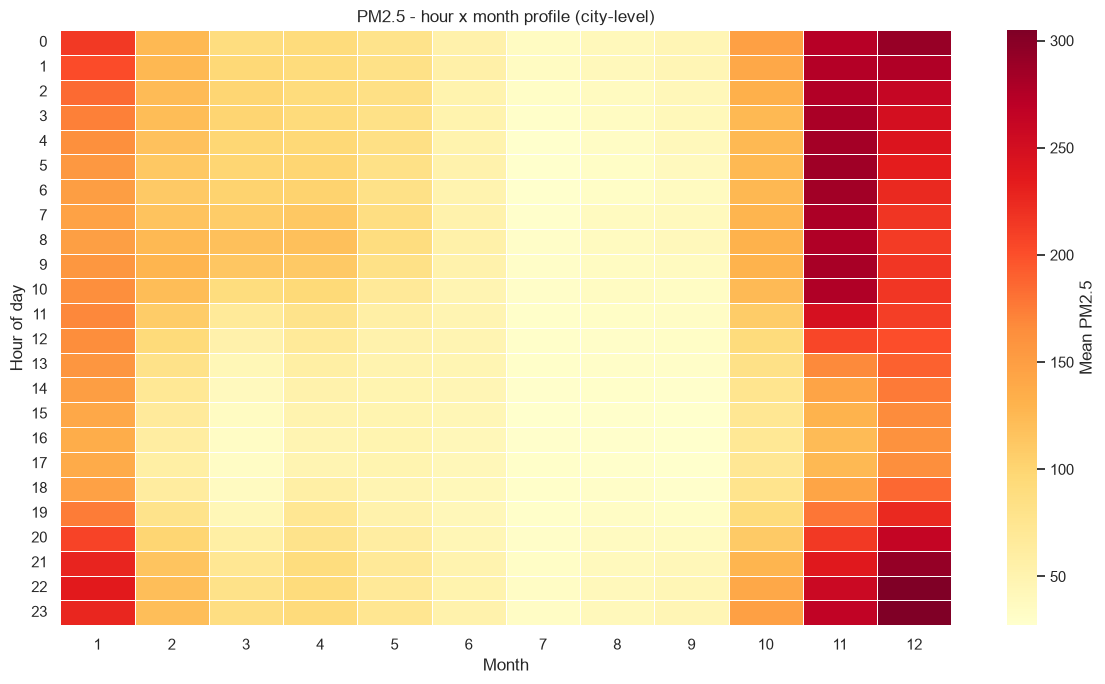

In [6]:
# Cell 6: Temporal EDA
df1 = df1.copy()
df1["hour"]      = df1["timestamp"].dt.hour
df1["month"]     = df1["timestamp"].dt.month
df1["dayofweek"] = df1["timestamp"].dt.dayofweek
df1["season"]    = np.select(
    [df1["month"].isin([12, 1, 2]),
     df1["month"].isin([3, 4, 5]),
     df1["month"].isin([6, 7, 8, 9]),
     df1["month"].isin([10, 11])],
    ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"],
    default="Other")

pm25_col = "PM2.5 (µg/m³)"
sub = df1.dropna(subset=["timestamp", pm25_col])

# 6a. Diurnal PM2.5 by station
diurnal = (sub.groupby(["station_name", "hour"])[pm25_col]
             .mean().unstack("station_name").reindex(range(24)))
plt.figure(figsize=(12, 6))
for s in diurnal.columns:
    plt.plot(diurnal.index, diurnal[s], label=s)
plt.xticks(range(24)); plt.xlabel("Hour of day"); plt.ylabel("Mean PM2.5")
plt.title("Diurnal PM2.5 by station")
plt.legend(title="Station", bbox_to_anchor=(1.02, 1),
           loc="upper left", fontsize=8)
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# 6b. Weekly PM2.5 by station
weekly = (sub.groupby(["dayofweek", "station_name"])[pm25_col]
            .mean().unstack("station_name").reindex(range(7)))
weekly.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.figure(figsize=(12, 6))
for s in weekly.columns:
    plt.plot(weekly.index, weekly[s], marker="o", label=s)
plt.xlabel("Day of week"); plt.ylabel("Mean PM2.5")
plt.title("Weekly PM2.5 by station")
plt.legend(title="Station", bbox_to_anchor=(1.02, 1),
           loc="upper left", fontsize=8)
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# 6c. Monthly heatmap (station x month)
monthly = (sub.pivot_table(index="station_name", columns="month",
                           values=pm25_col, aggfunc="mean")
             .reindex(columns=range(1, 13)))
monthly.columns = ["Jan","Feb","Mar","Apr","May","Jun",
                   "Jul","Aug","Sep","Oct","Nov","Dec"]
plt.figure(figsize=(14, 7))
sns.heatmap(monthly, cmap="YlOrRd", linewidths=0.3,
            cbar_kws={"label": "Mean PM2.5"})
plt.title("Monthly PM2.5 by station")
plt.xlabel("Month"); plt.ylabel("Station")
plt.tight_layout(); plt.show()

# 6d. Seasonal boxplot + strip
station_season = sub.groupby(["station_name", "season"])[pm25_col].mean().reset_index()
season_order = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
plt.figure(figsize=(11, 6))
sns.boxplot(data=station_season, x="season", y=pm25_col,
            order=season_order, showfliers=False)
sns.stripplot(data=station_season, x="season", y=pm25_col,
              order=season_order, color="black", alpha=0.7, jitter=0.12)
plt.title("Seasonal station-mean PM2.5")
plt.tight_layout(); plt.show()

# 6e. Normalized hourly & monthly profiles for all pollutants
hourly_pol  = df1.groupby("hour")[POLLUTANTS].mean()
monthly_pol = df1.groupby("month")[POLLUTANTS].mean()
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
(hourly_pol  / hourly_pol.max() ).plot(ax=axes[0], marker="o")
axes[0].set_title("Normalized diurnal profile per pollutant")
axes[0].legend(fontsize=7, ncol=2)
(monthly_pol / monthly_pol.max()).plot(ax=axes[1], marker="o")
axes[1].set_title("Normalized monthly profile per pollutant")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

# 6f. Hour x month heatmap (city-level PM2.5)
city_pm = (df1.groupby("timestamp")[pm25_col].mean()
              .to_frame("pm25").dropna().reset_index())
city_pm["hour"]  = city_pm["timestamp"].dt.hour
city_pm["month"] = city_pm["timestamp"].dt.month
pivot = city_pm.pivot_table(index="hour", columns="month",
                            values="pm25", aggfunc="mean")
plt.figure(figsize=(12, 7))
sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.4,
            cbar_kws={"label": "Mean PM2.5"})
plt.ylabel("Hour of day"); plt.xlabel("Month")
plt.title("PM2.5 - hour x month profile (city-level)")
plt.yticks(rotation=0); plt.tight_layout(); plt.show()

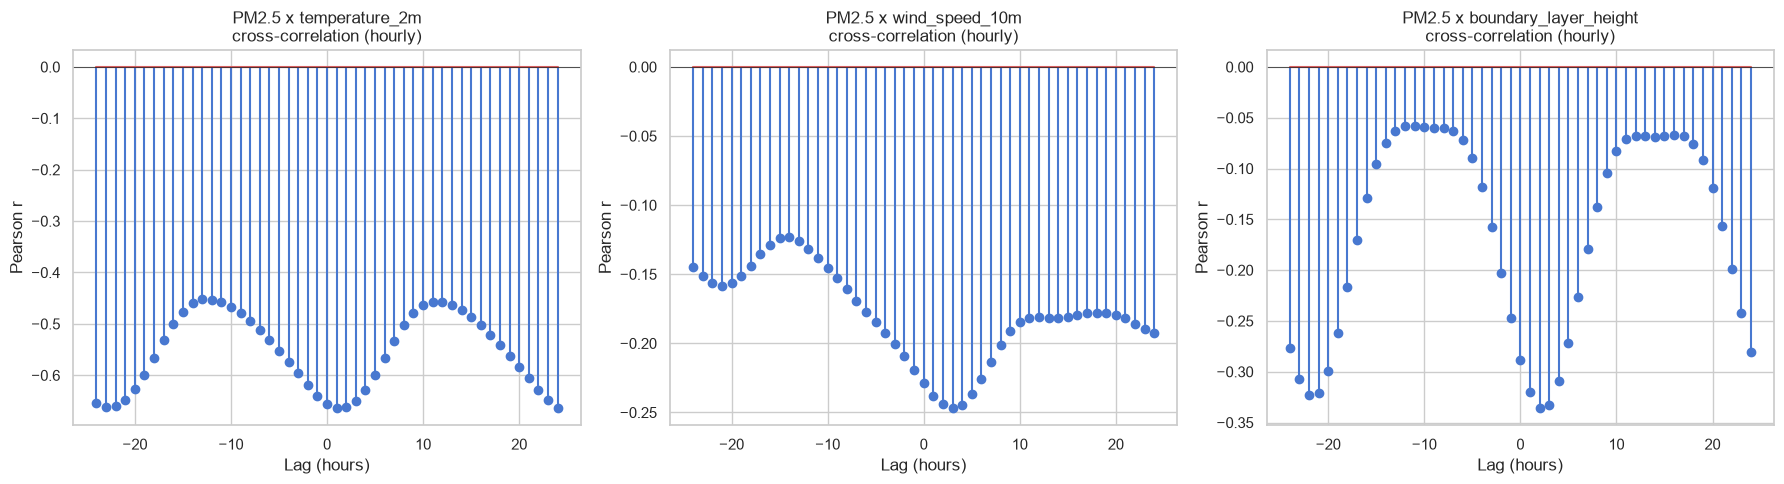

PM2.5 (µg/m³)             ADF p(level)=0.0001  p(diff)=0.0000
temperature_2m            ADF p(level)=0.2227  p(diff)=0.0000


In [7]:
# Cell 7: Time-series statistics
city = df1.groupby("timestamp")[POLLUTANTS + METEO].mean().sort_index()

def lagged_ccf(series_a, series_b, max_lag=24):
    s = city[[series_a, series_b]].dropna()
    lags = list(range(-max_lag, max_lag + 1))
    vals = [s[series_a].corr(s[series_b].shift(l)) for l in lags]
    return lags, vals

meteo_ccf = [c for c in ["temperature_2m", "wind_speed_10m",
                         "boundary_layer_height"] if c in city.columns]
if meteo_ccf:
    fig, axes = plt.subplots(1, len(meteo_ccf),
                             figsize=(6 * len(meteo_ccf), 5), squeeze=False)
    for ax, met in zip(axes.flatten(), meteo_ccf):
        lags, vals = lagged_ccf("PM2.5 (µg/m³)", met, max_lag=24)
        ax.stem(lags, vals)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_title(f"PM2.5 x {met}\ncross-correlation (hourly)")
        ax.set_xlabel("Lag (hours)"); ax.set_ylabel("Pearson r")
    plt.tight_layout(); plt.show()

def granger_report(df_in, target, driver, max_lag=12):
    s = df_in[[target, driver]].dropna()
    if len(s) < max_lag * 10:
        return None
    try:
        res = grangercausalitytests(s[[target, driver]],
                                    maxlag=max_lag, verbose=False)
    except Exception:
        return None
    pvals = {lag: res[lag][0]["ssr_ftest"][1] for lag in res}
    best  = min(pvals, key=pvals.get)
    return {"driver": driver, "best_lag": best, "min_p": pvals[best]}

rows = [granger_report(city, "PM2.5 (µg/m³)", met)
        for met in METEO if met in city.columns]
gr = pd.DataFrame([r for r in rows if r])
if not gr.empty:
    print("Granger tests (meteo -> PM2.5):\n", gr.sort_values("min_p").round(4))

for col in ["PM2.5 (µg/m³)", "temperature_2m"]:
    if col in city.columns:
        s = city[col].dropna()
        if len(s) > 10:
            p_level = adfuller(s)[1]
            p_diff  = adfuller(s.diff().dropna())[1]
            print(f"{col:25s} ADF p(level)={p_level:.4f}  p(diff)={p_diff:.4f}")

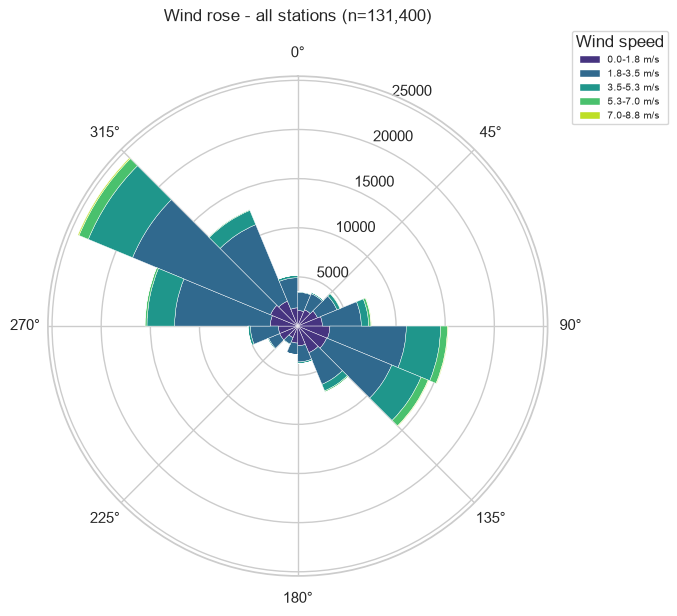

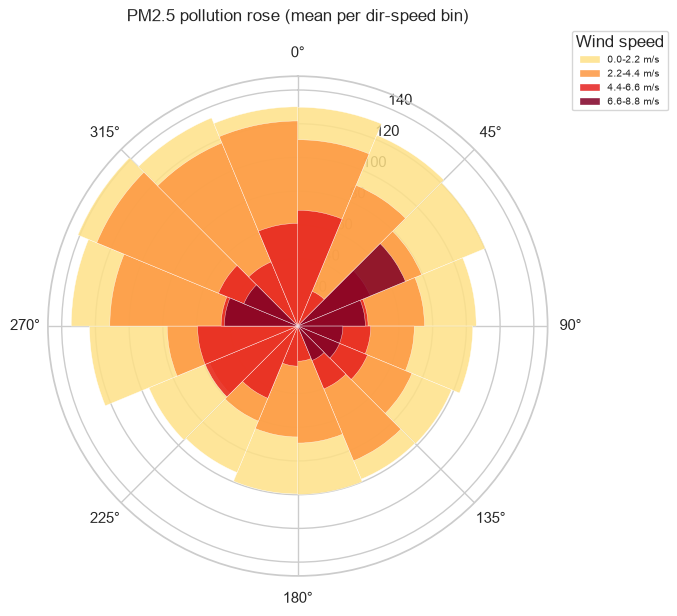

Valid rose rows per season:
 season
Monsoon         39608
Pre-monsoon     32240
Winter          31278
Post-monsoon    21393
Name: count, dtype: int64


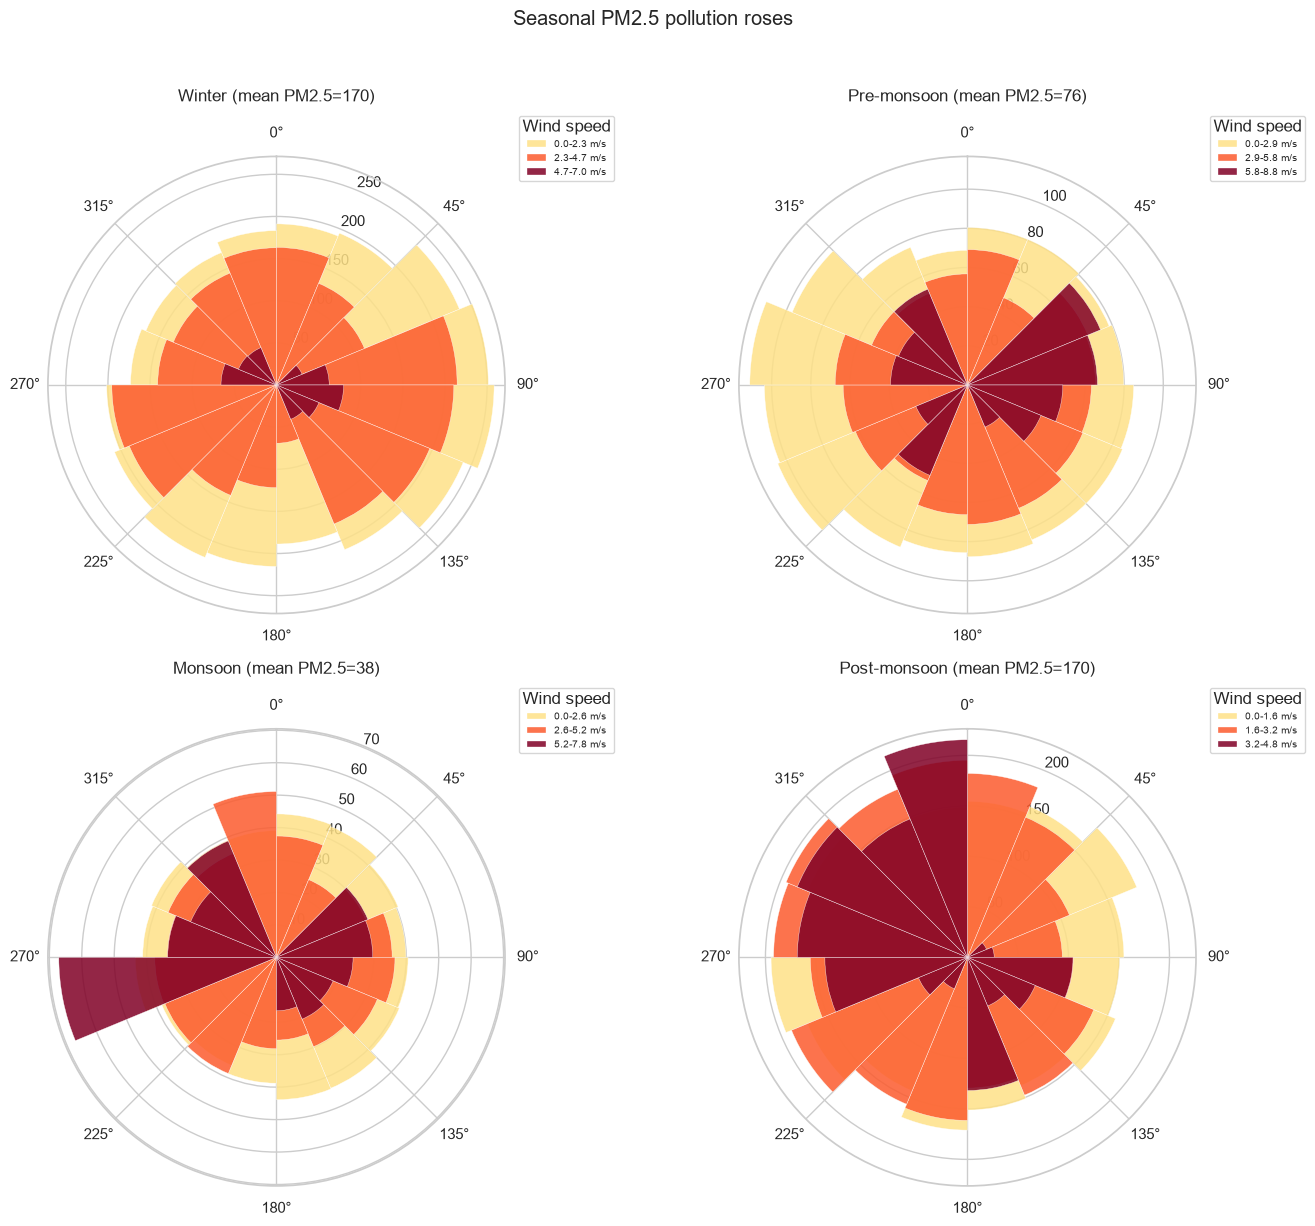

In [8]:
# Cell 8: Wind & pollution roses (custom, dependency-free)
def draw_wind_rose(ax, directions_deg, speeds, n_dir=16, n_spd=5,
                   title="Wind rose"):
    dir_edges = np.linspace(0, 360, n_dir + 1)
    spd_edges = np.linspace(0, np.nanmax(speeds), n_spd + 1)
    d_idx = np.clip(np.digitize(np.mod(directions_deg, 360), dir_edges) - 1,
                    0, n_dir - 1)
    s_idx = np.clip(np.digitize(speeds, spd_edges) - 1, 0, n_spd - 1)
    counts = np.zeros((n_spd, n_dir))
    np.add.at(counts, (s_idx, d_idx), 1)
    theta = np.deg2rad((dir_edges[:-1] + dir_edges[1:]) / 2)
    width = np.deg2rad(360 / n_dir)
    colors = plt.cm.viridis(np.linspace(0.15, 0.9, n_spd))
    bottom = np.zeros(n_dir)
    for i in range(n_spd):
        ax.bar(theta, counts[i], width=width, bottom=bottom, color=colors[i],
               edgecolor="white", linewidth=0.3,
               label=f"{spd_edges[i]:.1f}-{spd_edges[i+1]:.1f} m/s")
        bottom += counts[i]
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_title(title, pad=18)
    ax.legend(title="Wind speed", loc="upper right",
              bbox_to_anchor=(1.25, 1.1), fontsize=7)

def draw_pollution_rose(ax, directions_deg, speeds, values,
                        n_dir=16, n_spd=4, title="Pollution rose"):
    dir_edges = np.linspace(0, 360, n_dir + 1)
    spd_edges = np.linspace(0, np.nanmax(speeds), n_spd + 1)
    d_idx = np.clip(np.digitize(np.mod(directions_deg, 360), dir_edges) - 1,
                    0, n_dir - 1)
    s_idx = np.clip(np.digitize(speeds, spd_edges) - 1, 0, n_spd - 1)
    vals = np.full((n_spd, n_dir), np.nan)
    for s in range(n_spd):
        for d in range(n_dir):
            mask = (s_idx == s) & (d_idx == d)
            if mask.any():
                vals[s, d] = np.nanmean(values[mask])
    theta = np.deg2rad((dir_edges[:-1] + dir_edges[1:]) / 2)
    width = np.deg2rad(360 / n_dir)
    colors = plt.cm.YlOrRd(np.linspace(0.2, 1, n_spd))
    for i in range(n_spd):
        heights = np.nan_to_num(vals[i])
        ax.bar(theta, heights, width=width, color=colors[i], alpha=0.85,
               edgecolor="white", linewidth=0.3,
               label=f"{spd_edges[i]:.1f}-{spd_edges[i+1]:.1f} m/s")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_title(title, pad=18)
    ax.legend(title="Wind speed", loc="upper right",
              bbox_to_anchor=(1.25, 1.1), fontsize=7)

wr = df1.dropna(subset=["wind_direction_10m", "wind_speed_10m"])
if len(wr) > 0:
    fig = plt.figure(figsize=(7, 7))
    ax  = fig.add_subplot(111, polar=True)
    draw_wind_rose(ax, wr["wind_direction_10m"].values,
                   wr["wind_speed_10m"].values,
                   title=f"Wind rose - all stations (n={len(wr):,})")
    plt.tight_layout(); plt.show()

    pr = df1.dropna(subset=["wind_direction_10m", "wind_speed_10m",
                            "PM2.5 (µg/m³)"])
    fig = plt.figure(figsize=(7, 7))
    ax  = fig.add_subplot(111, polar=True)
    draw_pollution_rose(ax, pr["wind_direction_10m"].values,
                        pr["wind_speed_10m"].values,
                        pr["PM2.5 (µg/m³)"].values,
                        title="PM2.5 pollution rose (mean per dir-speed bin)")
    plt.tight_layout(); plt.show()

    SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
    print("Valid rose rows per season:\n", pr["season"].value_counts())
    fig, axes = plt.subplots(2, 2, subplot_kw={"polar": True}, figsize=(14, 12))
    for ax, season in zip(axes.flatten(), SEASONS):
        sub = pr[pr["season"] == season]
        if sub.empty:
            ax.text(0.5, 0.5, f"{season}\nno valid data",
                    transform=ax.transAxes, ha="center", va="center",
                    fontsize=12, color="grey")
            ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
            ax.set_title(season, pad=18); continue
        draw_pollution_rose(
            ax, sub["wind_direction_10m"].values,
            sub["wind_speed_10m"].values, sub["PM2.5 (µg/m³)"].values,
            n_spd=3,
            title=f"{season} (mean PM2.5={sub['PM2.5 (µg/m³)'].mean():.0f})")
    plt.suptitle("Seasonal PM2.5 pollution roses", y=1.02)
    plt.tight_layout(); plt.show()

       station_name    lat    lon    pm25     n    no2
0            Alipur  28.82  77.15  100.64  8499  36.57
1       Anand Vihar  28.65  77.32  121.88  8144  64.46
2            Bawana  28.79  77.05  123.44  8560  21.98
3               DTU  28.75  77.11   76.96  8348  39.07
4   Dwarka Sector 8  28.57  77.07  101.92  8602  55.75
5               ITO  28.63  77.24  102.76  8272  68.48
6        Lodhi Road  28.59  77.23   86.34  7118  36.14
7            Mundka  28.68  77.08  115.49  8502  48.43
8         Najafgarh  28.57  76.93   79.28  8276  51.88
9        Patparganj  28.62  77.29  102.03  8585  50.13
10     Punjabi Bagh  28.67  77.13  109.94  8100  36.30
11       R.K. Puram  28.56  77.19  110.34  8358  41.87
12           Rohini  28.73  77.12  115.93  8636  35.92
13         Shadipur  28.65  77.15   91.84  8047  65.32
14      Vivek Vihar  28.67  77.32  114.71  8472  39.16


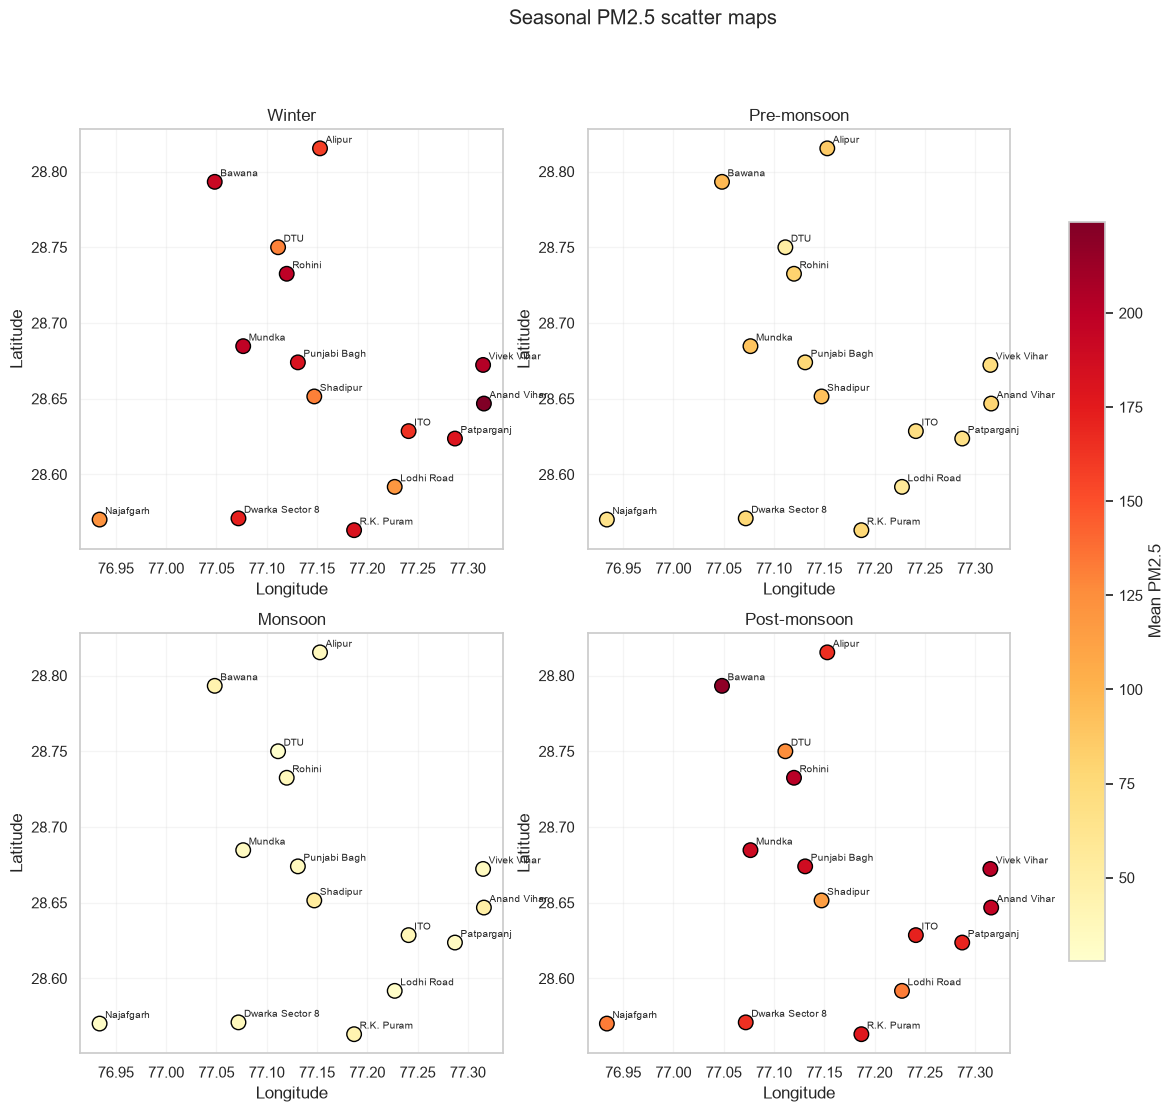

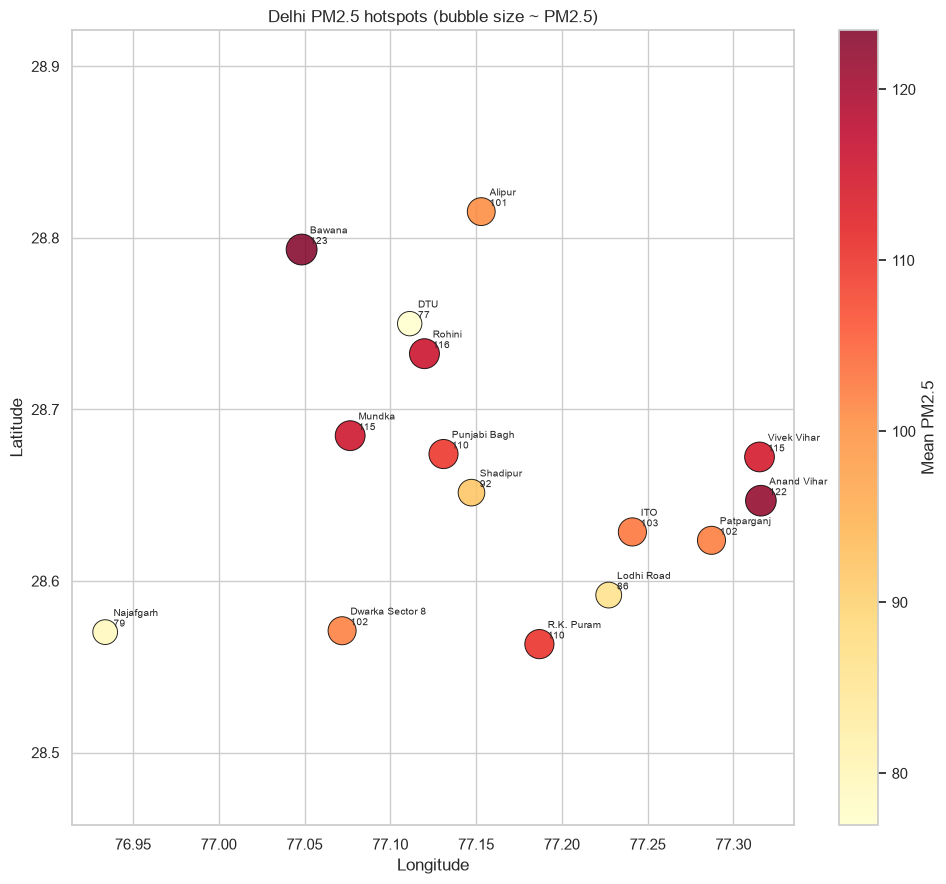

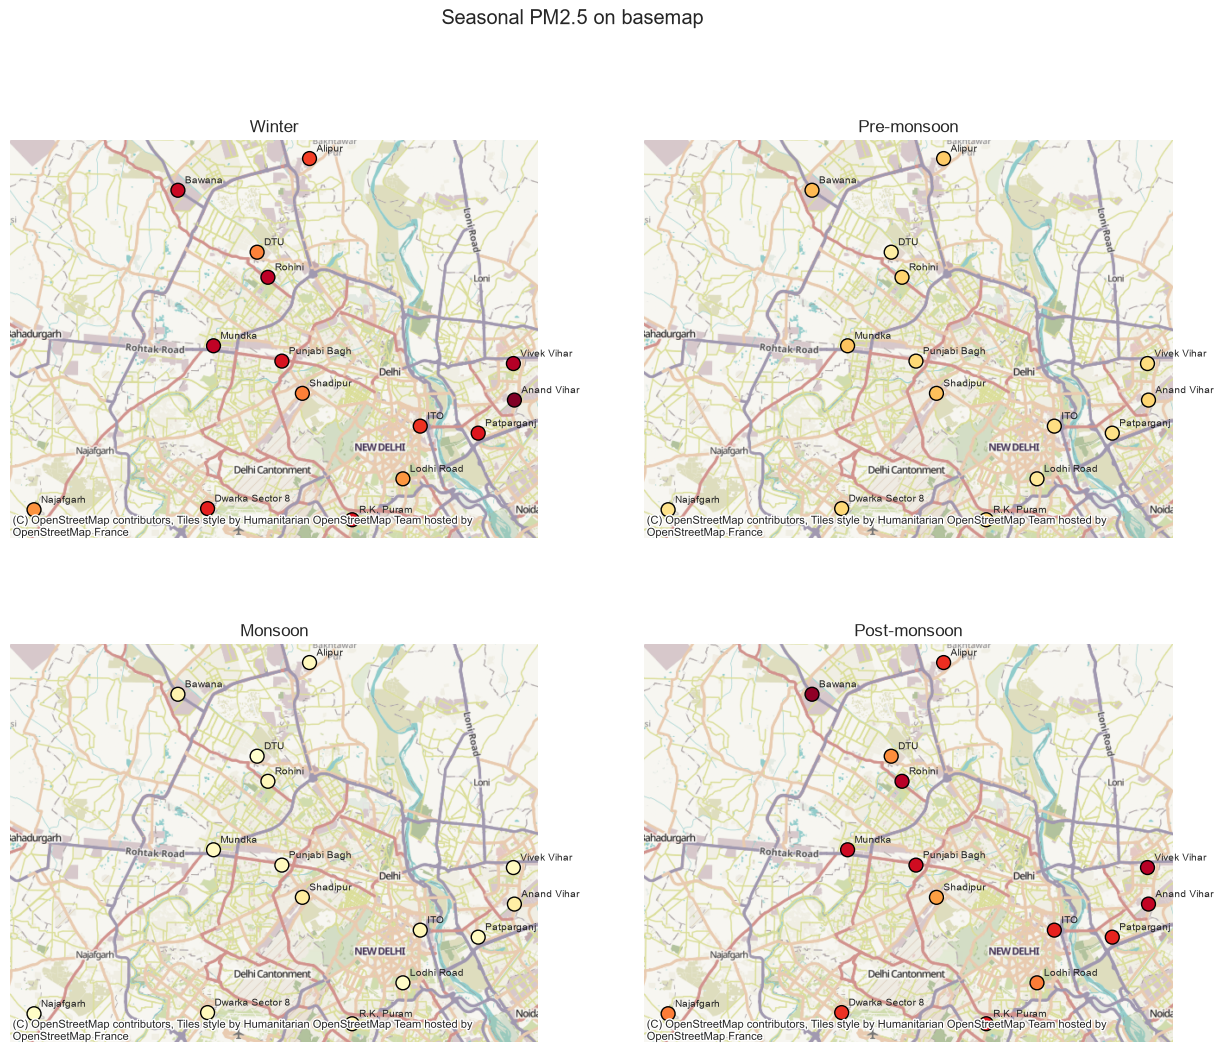

In [9]:
# Cell 9: Spatial analysis
st = (df1.groupby("station_name")
        .agg(lat=("latitude_x", "first"),
             lon=("longitude_x", "first"),
             pm25=("PM2.5 (µg/m³)", "mean"),
             n=("PM2.5 (µg/m³)", "count"))
        .reset_index())
if "NO2 (µg/m³)" in df1.columns:
    st["no2"] = df1.groupby("station_name")["NO2 (µg/m³)"].mean().values
st = st.dropna(subset=["lat", "lon", "pm25"])
print(st.round(2))

# 9a. Seasonal scatter maps
season_agg = (df1.dropna(subset=["latitude_x", "longitude_x",
                                 "PM2.5 (µg/m³)", "season"])
                 .groupby(["station_name", "season"])
                 .agg(lat=("latitude_x", "first"),
                      lon=("longitude_x", "first"),
                      pm25=("PM2.5 (µg/m³)", "mean"))
                 .reset_index())
SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]
vmin, vmax = season_agg["pm25"].min(), season_agg["pm25"].max()
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
sc = None
for ax, season in zip(axes.flat, SEASONS):
    d = season_agg[season_agg["season"] == season]
    if d.empty:
        ax.set_title(f"{season} (no data)"); ax.axis("off"); continue
    sc = ax.scatter(d["lon"], d["lat"], c=d["pm25"], cmap="YlOrRd",
                    vmin=vmin, vmax=vmax, s=110, edgecolors="black")
    for _, row in d.iterrows():
        ax.annotate(row["station_name"], (row["lon"], row["lat"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7)
    ax.set_title(season); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.grid(alpha=0.2)
if sc is not None:
    fig.colorbar(sc, ax=axes.ravel().tolist(),
                 label="Mean PM2.5", shrink=0.8)
fig.suptitle("Seasonal PM2.5 scatter maps"); plt.show()

# 9b. Bubble hotspot map
fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(st["lon"], st["lat"], s=st["pm25"] * 4,
                c=st["pm25"], cmap="YlOrRd", edgecolor="black",
                linewidth=0.7, alpha=0.85, vmin=st["pm25"].min())
for _, row in st.iterrows():
    ax.annotate(f"{row.station_name}\n{row.pm25:.0f}",
                (row.lon, row.lat), xytext=(6, 4),
                textcoords="offset points", fontsize=7)
plt.colorbar(sc, ax=ax, label="Mean PM2.5")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Delhi PM2.5 hotspots (bubble size ~ PM2.5)")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()

# 9c. Optional: basemap layer (requires geopandas + contextily + internet)
try:
    import geopandas as gpd
    import contextily as ctx
    gdf = gpd.GeoDataFrame(
        season_agg,
        geometry=gpd.points_from_xy(season_agg["lon"], season_agg["lat"]),
        crs="EPSG:4326").to_crs(epsg=3857)
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    for ax, season in zip(axes.flat, SEASONS):
        d = gdf[gdf["season"] == season]
        if d.empty:
            ax.axis("off"); continue
        d.plot(ax=ax, column="pm25", cmap="YlOrRd",
               vmin=vmin, vmax=vmax, markersize=100,
               edgecolor="black", legend=False, zorder=2)
        for _, row in d.iterrows():
            ax.annotate(row["station_name"],
                        (row.geometry.x, row.geometry.y),
                        xytext=(5, 5), textcoords="offset points",
                        fontsize=7)
        try:
            ctx.add_basemap(ax)
        except Exception:
            pass
        ax.set_title(season); ax.set_axis_off()
    fig.suptitle("Seasonal PM2.5 on basemap"); plt.show()
except Exception as e:
    print("Basemap layer skipped:", e)

# 9d. Optional: Folium interactive map
try:
    import folium
    import branca.colormap as cm
    m = folium.Map(location=[st["lat"].mean(), st["lon"].mean()],
                   zoom_start=11)
    color_scale = cm.LinearColormap(
        colors=["#ffffb2", "#fecc5c", "#fd8d3c", "#e31a1c"],
        vmin=st["pm25"].min(), vmax=st["pm25"].max(),
        caption="Mean PM2.5 (µg/m³)")
    for _, row in st.iterrows():
        folium.CircleMarker(
            location=[row["lat"], row["lon"]], radius=8,
            color="black", weight=1, fill=True,
            fill_color=color_scale(row["pm25"]),
            fill_opacity=0.85, tooltip=row["station_name"],
            popup=f"{row['station_name']}<br>Mean PM2.5: {row['pm25']:.1f}"
        ).add_to(m)
    color_scale.add_to(m)
    m.save("delhi_pm25_map.html")
    display(m)
except Exception as e:
    print("Folium map skipped:", e)

Explained variance ratio:
  PC1: 0.484  (cumulative 0.484)
  PC2: 0.153  (cumulative 0.637)
  PC3: 0.112  (cumulative 0.749)
  PC4: 0.103  (cumulative 0.851)
  PC5: 0.085  (cumulative 0.936)
  PC6: 0.044  (cumulative 0.980)
  PC7: 0.020  (cumulative 1.000)

Loadings (first 3 PCs):
                 PC1   PC2   PC3
PM2.5 (µg/m³)  0.44  0.24 -0.36
PM10 (µg/m³)   0.45  0.27 -0.35
NO (µg/m³)     0.39 -0.22  0.05
NO2 (µg/m³)    0.37 -0.16  0.23
NH3 (µg/m³)    0.27  0.39  0.82
CO (mg/m³)     0.45 -0.14 -0.06
Ozone (µg/m³) -0.16  0.79 -0.12


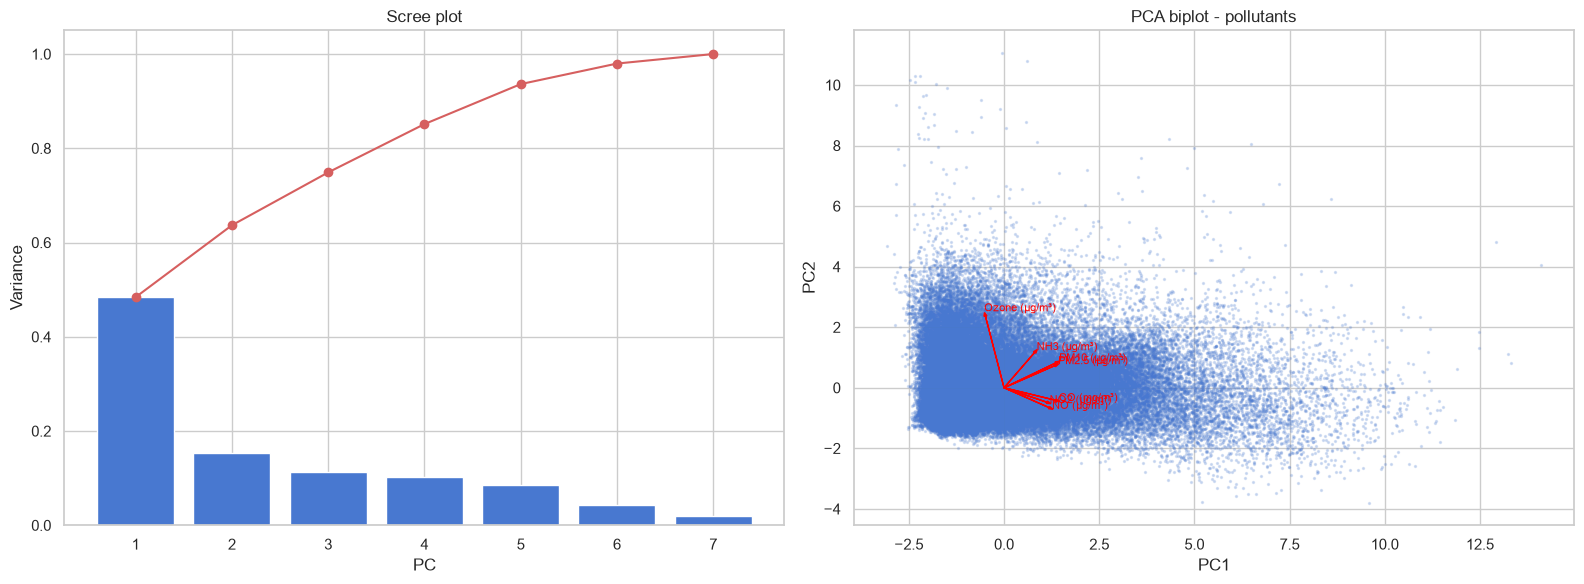

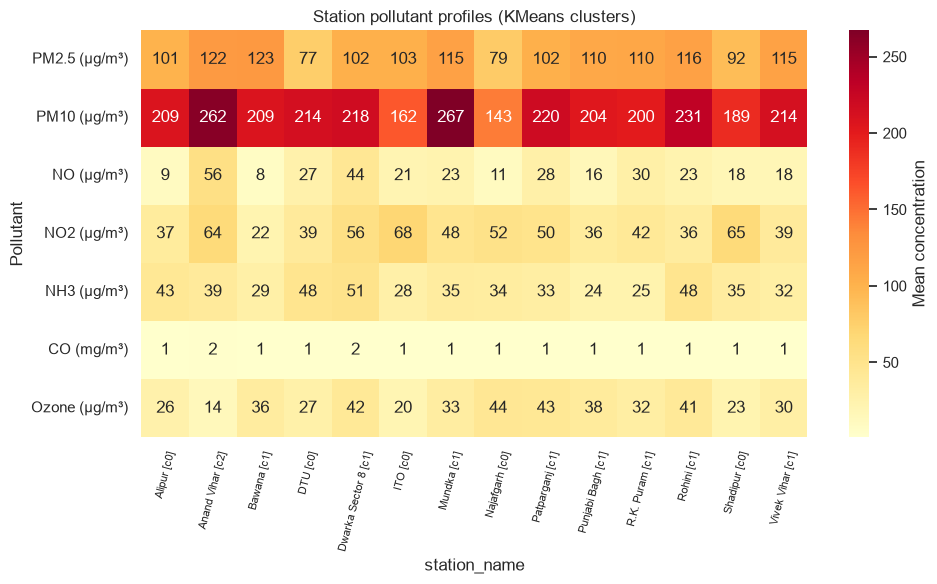

In [10]:
# Cell 10: PCA + KMeans on station pollutant profiles
X  = df1[POLLUTANTS].dropna()
Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=len(POLLUTANTS))
scores = pca.fit_transform(Xs)

print("Explained variance ratio:")
for i, v in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1}: {v:.3f}  "
          f"(cumulative {pca.explained_variance_ratio_[:i+1].sum():.3f})")

loadings = pd.DataFrame(pca.components_.T, index=POLLUTANTS,
                        columns=[f"PC{i+1}" for i in range(len(POLLUTANTS))])
print("\nLoadings (first 3 PCs):\n", loadings.iloc[:, :3].round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(range(1, len(pca.explained_variance_ratio_) + 1),
            pca.explained_variance_ratio_)
axes[0].plot(range(1, len(pca.explained_variance_ratio_) + 1),
             np.cumsum(pca.explained_variance_ratio_), "r-o")
axes[0].set_title("Scree plot")
axes[0].set_xlabel("PC"); axes[0].set_ylabel("Variance")
axes[1].scatter(scores[:, 0], scores[:, 1], s=2, alpha=0.2)
for i, p in enumerate(POLLUTANTS):
    axes[1].arrow(0, 0, pca.components_[0, i] * 3,
                  pca.components_[1, i] * 3,
                  color="red", head_width=0.08)
    axes[1].text(pca.components_[0, i] * 3.2,
                 pca.components_[1, i] * 3.2, p,
                 fontsize=8, color="red")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("PCA biplot - pollutants")
plt.tight_layout(); plt.show()

station_profile = df1.groupby("station_name")[POLLUTANTS].mean().dropna()
if len(station_profile) >= 3:
    Z  = StandardScaler().fit_transform(station_profile)
    km = KMeans(n_clusters=min(3, len(station_profile)),
                random_state=RANDOM_STATE, n_init=10).fit(Z)
    station_profile["cluster"] = km.labels_
    plt.figure(figsize=(10, 6))
    sns.heatmap(station_profile[POLLUTANTS].T, cmap="YlOrRd",
                annot=True, fmt=".0f",
                cbar_kws={"label": "Mean concentration"})
    ax = plt.gca()
    ax.set_xticklabels(
        [f"{s} [c{c}]" for s, c in
         zip(station_profile.index, station_profile["cluster"])],
        rotation=75, fontsize=8)
    plt.title("Station pollutant profiles (KMeans clusters)")
    plt.ylabel("Pollutant"); plt.tight_layout(); plt.show()

                            OLS Regression Results                            
Dep. Variable:          PM2.5 (µg/m³)   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     3075.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:48:10   Log-Likelihood:                -46291.
No. Observations:                8760   AIC:                         9.260e+04
Df Residuals:                    8752   BIC:                         9.265e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                   157.21

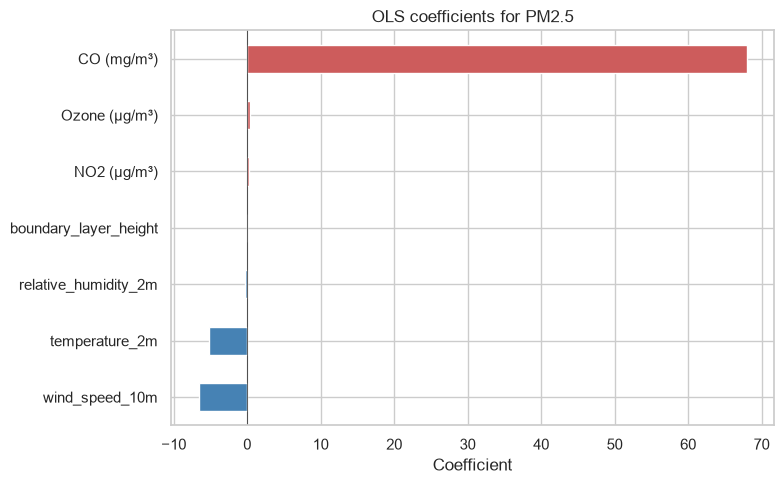

In [11]:
# Cell 11: OLS regression + coefficient plot
reg_df     = city.dropna(subset=["PM2.5 (µg/m³)"])
predictors = [c for c in ["temperature_2m", "wind_speed_10m",
                          "relative_humidity_2m", "boundary_layer_height",
                          "NO2 (µg/m³)", "CO (mg/m³)", "Ozone (µg/m³)"]
              if c in reg_df.columns]
if predictors:
    Xr = sm.add_constant(reg_df[predictors])
    yr = reg_df["PM2.5 (µg/m³)"]
    model = sm.OLS(yr, Xr).fit()
    print(model.summary())

    coefs = model.params.drop("const").sort_values()
    plt.figure(figsize=(8, 5))
    colors = np.where(coefs < 0, "steelblue", "indianred")
    coefs.plot(kind="barh", color=colors)
    plt.axvline(0, color="k", lw=0.5)
    plt.title("OLS coefficients for PM2.5")
    plt.xlabel("Coefficient"); plt.tight_layout(); plt.show()

In [12]:
# Cell 12: Summary
pm25_col = "PM2.5 (µg/m³)"
summary = {
    "rows":              len(df1),
    "stations":          int(df1["station_name"].nunique()),
    "time_span":         (df1["timestamp"].min(), df1["timestamp"].max()),
    "top_PM2.5_station": df1.groupby("station_name")[pm25_col].mean().idxmax(),
}
if "corr_p" in globals() and pm25_col in corr_p.columns:
    others = corr_p[pm25_col].drop(pm25_col)
    summary["strongest_neg_corr_PM25"] = others.idxmin()
    summary["strongest_pos_corr_PM25"] = others.idxmax()
if "pca" in globals():
    summary["PC1_variance"] = round(float(pca.explained_variance_ratio_[0]), 3)
if "model" in globals():
    summary["OLS_R2"] = round(float(model.rsquared), 3)

for k, v in summary.items():
    print(f"{k:30s}: {v}")

rows                          : 131400
stations                      : 15
time_span                     : (Timestamp('2025-01-01 00:00:00'), Timestamp('2025-12-31 23:00:00'))
top_PM2.5_station             : Bawana
strongest_neg_corr_PM25       : temperature_2m
strongest_pos_corr_PM25       : PM10 (µg/m³)
PC1_variance                  : 0.484
OLS_R2                        : 0.711
